# Driving v2 · Rung 1: does the network work when it can see the dot?

**Question:** if the network is told where the dot is *relative to the robot*, can it copy the expert's wheel commands?

This is an **oracle** test. The dot's position comes from the simulator, not from a sensor. Later, a camera replaces it. If this rung fails, a camera will not help.

**One change at a time.** Three models, same network, same data, same training. Only the inputs differ:

| Model | Inputs |
|---|---|
| `wheels` | 12 wheel features (angles, speeds, summaries) |
| `wheels+start_dot` | + sin/cos of the dot's direction **at the start** (the old setup) |
| `wheels+live_dot` | + distance and sin/cos of the dot's direction **relative to the robot, every step** |

**Outputs (the expert's):** four wheel-velocity commands + PARK.
Arm torques are not in this dataset (it was collected driving-only), so they come later.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DATA = Path('../driving_30/data/expert_30hz')
records = [json.loads(line) for line in open(DATA / 'episodes.jsonl')]
split_of = {p['bearing_deg']: p['split'] for p in json.loads((DATA / 'split_plan.json').read_text())}

# Repeated runs are byte-identical: keep one trajectory per unique hash.
unique = {}
for r in records:
    unique.setdefault(r['trajectory_hash'], r)
episodes = sorted(unique.values(), key=lambda r: r['bearing_deg'])
print(f'{len(records)} executions -> {len(episodes)} unique trajectories')
print(pd.Series([split_of[r["bearing_deg"]] for r in episodes]).value_counts().to_dict())

1500 executions -> 30 unique trajectories
{'train': 21, 'holdout': 5, 'test': 4}


### Build the inputs

`base_pose` is the simulator's true robot pose: x, y, z, then a quaternion (x, y, z, w). It is used **only** to compute the oracle dot features. It is not given to the network.

Live dot features at each step:
- `dot_distance_m`: horizontal distance from the robot to the dot
- `dot_sin`, `dot_cos`: direction of the dot, measured from where the robot is facing

In [2]:
WHEEL = list(range(12))      # first 12 columns of the saved x: wheel features
START_DOT = [12, 13]         # saved sin/cos of the initial bearing

def yaw(q):                  # quaternion (x, y, z, w) -> heading in radians
    x, y, z, w = q.T
    return np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))

def live_dot(pose, target):
    dx, dy = target[0] - pose[:, 0], target[1] - pose[:, 1]
    angle = np.arctan2(dy, dx) - yaw(pose[:, 3:7])
    return np.c_[np.hypot(dx, dy), np.sin(angle), np.cos(angle)].astype(np.float32)

rows = []
for r in episodes:
    with np.load(DATA / r['archive']) as a:
        target = np.array(r['manifest']['target_position_world_m'])
        rows.append(dict(bearing=r['bearing_deg'], split=split_of[r['bearing_deg']],
                         x=a['x'], live=live_dot(a['base_pose'], target),
                         wheels=a['wheels'], park=a['park'].ravel()))

INPUTS = {
    'wheels':           lambda e: e['x'][:, WHEEL],
    'wheels+start_dot': lambda e: e['x'][:, WHEEL + START_DOT],
    'wheels+live_dot':  lambda e: np.c_[e['x'][:, WHEEL], e['live']],
}
e = rows[0]
print('Bearing', e['bearing'], '| rows', len(e['x']))
pd.DataFrame(e['live'], columns=['dot_distance_m', 'dot_sin', 'dot_cos']).iloc[[0, 10, 30, -1]].round(3)

Bearing 12 | rows 96


,dot_distance_m,dot_sin,dot_cos
0,1.100,0.208,0.978
10,1.102,0.083,0.997
30,1.003,0.014,1.000
95,0.707,0.014,1.000


### Collision check at t = 0

Every run starts at rest. Do the inputs at t = 0 differ between bearings? If they don't, the network can't tell the runs apart, but the expert's first command still differs.

In [3]:
for name, f in INPUTS.items():
    first = np.array([f(e)[0] for e in rows]).round(6)
    print(f'{name:18s} distinct t=0 inputs: {len(np.unique(first, axis=0)):2d} of {len(rows)} bearings')
first_cmd = np.array([e['wheels'][0] for e in rows]).round(3)
print(f'{"expert":18s} distinct t=0 commands: {len(np.unique(first_cmd, axis=0)):2d} of {len(rows)} bearings')

wheels             distinct t=0 inputs:  1 of 30 bearings
wheels+start_dot   distinct t=0 inputs: 30 of 30 bearings
wheels+live_dot    distinct t=0 inputs: 30 of 30 bearings
expert             distinct t=0 commands:  5 of 30 bearings


### Prediction, written before training

- `wheels`: poor everywhere. It can't tell the bearings apart.
- `wheels+start_dot`: much better than `wheels`.
- `wheels+live_dot`: best, especially on test bearings, because the dot direction stays current after the robot turns.

These are **offline** scores on the expert's own states. They don't yet show the robot driving.

In [4]:
SEED, EPOCHS, LR, PARK_WEIGHT = 7, 300, 0.01, 0.1
torch.set_num_threads(1)

class Policy(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
        self.wheels = nn.Linear(16, 4)
        self.park = nn.Linear(16, 1)
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h), self.park(h).squeeze(1)

def stack(eps, f):
    X = torch.from_numpy(np.concatenate([f(e) for e in eps]).astype(np.float32))
    W = torch.from_numpy(np.concatenate([e['wheels'] for e in eps]).astype(np.float32))
    P = torch.from_numpy(np.concatenate([e['park'] for e in eps]).astype(np.float32))
    # each trajectory counts equally, whatever its length
    w = torch.from_numpy(np.concatenate([np.full(len(e['x']), 1 / (len(e['x']) * len(eps))) for e in eps]).astype(np.float32))
    return X, W, P, w

def loss_fn(model, X, W, P, w, pos_weight):
    pw, pl = model(X)
    wheel_mse = (w * ((pw - W) ** 2).mean(1)).sum()
    park_bce = F.binary_cross_entropy_with_logits(pl, P, pos_weight=pos_weight)
    return wheel_mse + PARK_WEIGHT * park_bce, wheel_mse, park_bce

train = [e for e in rows if e['split'] == 'train']
test = [e for e in rows if e['split'] == 'test']      # holdout stays untouched
models, history = {}, []
for name, f in INPUTS.items():
    torch.manual_seed(SEED)
    Xtr, Wtr, Ptr, wtr = stack(train, f)
    Xte, Wte, Pte, wte = stack(test, f)
    pos_weight = (len(Ptr) - Ptr.sum()) / Ptr.sum()     # from training data only
    model = Policy(Xtr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for epoch in range(EPOCHS + 1):
        model.train()
        total, wm, pb = loss_fn(model, Xtr, Wtr, Ptr, wtr, pos_weight)
        with torch.no_grad():
            _, te_wm, _ = loss_fn(model, Xte, Wte, Pte, wte, pos_weight)
        history.append(dict(model=name, epoch=epoch, train_wheel_mse=wm.item(), test_wheel_mse=te_wm.item(), train_park_bce=pb.item()))
        if epoch < EPOCHS:
            opt.zero_grad(); total.backward(); opt.step()
    models[name] = model
    print(f'{name:18s} inputs={Xtr.shape[1]:2d}  train rows={len(Xtr)}  final train wheel MSE={wm.item():.4f}  test={te_wm.item():.4f}')
history = pd.DataFrame(history)
Path('models').mkdir(exist_ok=True)
for name, m in models.items():
    torch.save(m.state_dict(), f'models/rung1_{name.replace("+", "_")}.pt')

wheels             inputs=12  train rows=2965  final train wheel MSE=0.0704  test=0.0773


wheels+start_dot   inputs=14  train rows=2965  final train wheel MSE=0.0460  test=0.0416


wheels+live_dot    inputs=15  train rows=2965  final train wheel MSE=0.0342  test=0.0326


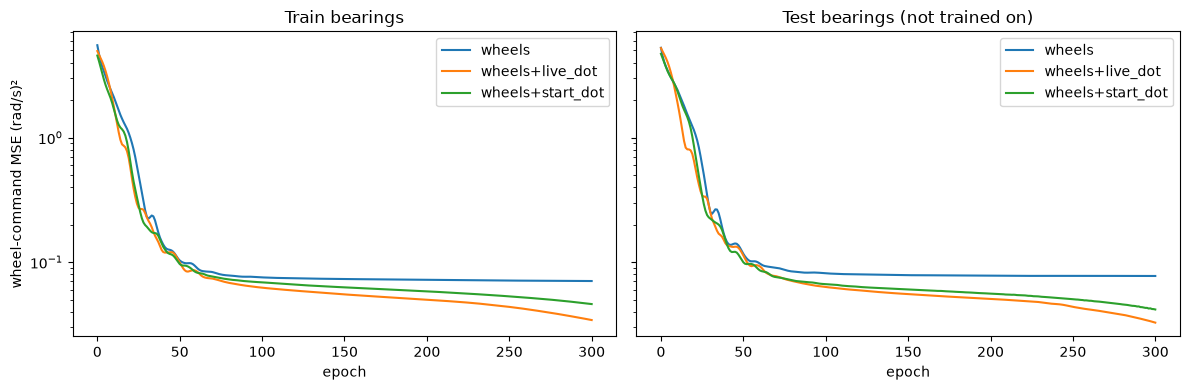

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, h in history.groupby('model'):
    ax[0].plot(h.epoch, h.train_wheel_mse, label=name)
    ax[1].plot(h.epoch, h.test_wheel_mse, label=name)
for a, t in zip(ax, ['Train bearings', 'Test bearings (not trained on)']):
    a.set(title=t, xlabel='epoch', yscale='log'); a.legend()
ax[0].set_ylabel('wheel-command MSE (rad/s)²')
plt.tight_layout(); plt.show()
# Test is plotted for inspection only; it does not choose the epoch (fixed at 300).

### Offline results

Per trajectory, then averaged. `n` is the number of bearings. Baseline: always command zero.

PARK: **hit** = predicted PARK on the expert's PARK row; **early rows** = rows predicted PARK before the expert parked.

In [6]:
def evaluate(model, f, eps):
    out = []
    for e in eps:
        with torch.no_grad():
            pw, pl = model(torch.from_numpy(f(e).astype(np.float32)))
        pw, prob = pw.numpy(), torch.sigmoid(pl).numpy()
        out.append(dict(bearing=e['bearing'], wheel_mae=np.abs(pw - e['wheels']).mean(),
                        zero_baseline_mae=np.abs(e['wheels']).mean(),
                        park_hit=bool(prob[-1] >= 0.5), early_park_rows=int((prob[:-1] >= 0.5).sum())))
    return pd.DataFrame(out)

results = []
for name, f in INPUTS.items():
    for split, eps in [('train', train), ('test', test)]:
        r = evaluate(models[name], f, eps).assign(model=name, split=split)
        results.append(r)
results = pd.concat(results)
summary = results.groupby(['split', 'model'], sort=False).agg(
    n=('bearing', 'size'), wheel_MAE=('wheel_mae', 'mean'), zero_baseline_MAE=('zero_baseline_mae', 'mean'),
    park_hits=('park_hit', 'sum'), early_park_rows=('early_park_rows', 'sum'))
summary.round(3)

,,n,wheel_MAE,zero_baseline_MAE,park_hits,early_park_rows
split,model,,,,,
train,wheels,21,0.087,1.995,21,100
test,wheels,4,0.086,2.040,4,19
train,wheels+start_dot,21,0.096,1.995,21,101
test,wheels+start_dot,4,0.095,2.040,4,21
train,wheels+live_dot,21,0.095,1.995,21,96
test,wheels+live_dot,4,0.097,2.040,4,19


### Test bearings, worst first

In [7]:
results[results.split == 'test'].pivot(index='bearing', columns='model', values='wheel_mae').round(3).sort_values('wheels+live_dot', ascending=False)

model,wheels,wheels+live_dot,wheels+start_dot
bearing,,,
24,0.103,0.106,0.111
132,0.083,0.102,0.097
108,0.084,0.095,0.088
204,0.075,0.088,0.085


### What this does **not** show

- **Offline only.** Scores use the expert's own states. The real test is closed-loop: the network drives, and its errors change what it sees next.
- **Oracle input.** The live dot comes from the simulator's true pose. A camera will replace it in rung 2.
- **No arm torques.** This dataset is driving-only.
- **Small n.** 21 training and 4 test bearings, one seed. The 4 test bearings were seen in earlier experiments. The 5 holdout bearings are not used here.
- **One copy of each trajectory.** The dataset repeats each of the 30 trajectories; repeats are identical and are dropped.

## Closed loop: the network drives the robot

Each model now drives the robot in the fast native PyBullet build (`comp0245-native-expert/build-clang19/policy_replay`), the same engine that collected the data. Headless, 1 kHz physics, 30 Hz decisions. The arm is held in its start pose.

For each of the 25 train and test bearings, the expert runs once and each model runs once from the same start:
- the expert runs until its PARK, then 0.5 s of drift;
- the model has until **expert PARK + 3 s** to issue its own PARK (probability ≥ 0.5, latched), then 0.5 s of drift.

The 5 holdout bearings are not run.

**Errors compare the model's base with the expert's base**: position (m) and heading (degrees), at PARK and at the end.

This cell reads saved rollouts. It doesn't run physics.

In [8]:
import replay_v2
closed = []
for name in ['wheels', 'wheels+start_dot', 'wheels+live_dot']:
    _, m, diff = replay_v2.load(name)
    closed.append(m)
    print(f'{name:18s} max NumPy vs native prediction difference: {diff:.1e}')
closed = pd.concat(closed)
closed.groupby(['split', 'model'], sort=False).agg(
    n=('bearing_deg', 'size'), parked=('parked', 'sum'),
    park_xy_error_m=('park_xy_error_m', 'mean'), park_yaw_error_deg=('park_yaw_error_deg', 'mean'),
    final_xy_error_m=('final_xy_error_m', 'mean'), final_yaw_error_deg=('final_yaw_error_deg', 'mean')).round(3)

wheels             max NumPy vs native prediction difference: 7.2e-07


wheels+start_dot   max NumPy vs native prediction difference: 1.8e-06


wheels+live_dot    max NumPy vs native prediction difference: 1.2e-06


,,n,parked,park_xy_error_m,park_yaw_error_deg,final_xy_error_m,final_yaw_error_deg
split,model,,,,,,
train,wheels,21,9,0.287,38.143,0.447,89.919
test,wheels,4,3,0.421,40.923,0.473,71.182
train,wheels+start_dot,21,10,0.275,43.575,0.361,74.568
test,wheels+start_dot,4,1,0.037,4.078,0.246,117.384
train,wheels+live_dot,21,19,0.153,14.917,0.182,18.577
test,wheels+live_dot,4,4,0.121,12.204,0.127,12.484


### Every bearing: final position error (m), worst first for the live-dot model

In [9]:
closed.pivot_table(index=['split', 'bearing_deg'], columns='model', values='final_xy_error_m').round(2)\
      .sort_values('wheels+live_dot', ascending=False)

model              wheels  wheels+live_dot  wheels+start_dot
split bearing_deg                                           
train 168            0.37             0.43              0.48
      156            0.45             0.30              0.34
      180            0.17             0.26              0.53
      192            0.06             0.23              0.21
test  204            0.03             0.20              0.39
train 216            0.12             0.18              0.34
      300            0.57             0.18              0.67
      288            0.53             0.18              0.79
      228            0.22             0.18              0.47
      312            0.58             0.17              0.51
      12             0.52             0.17              0.07
      264            0.41             0.17              0.85
      240            0.29             0.17              0.51
      252            0.36             0.16              0.52
test  24             0.58             0.16              0.04
train 84             0.69             0.16              0.20
      72             0.73             0.16              0.24
      36             0.65             0.16              0.06
      60             0.74             0.14              0.17
      336            0.53             0.14              0.09
      360            0.24             0.11              0.10
      348            0.51             0.10              0.10
test  108            0.68             0.08              0.27
train 120            0.65             0.07              0.32
test  132            0.59             0.07              0.28

## 3D replay: model vs ghost expert

Solid robot: the model. Cyan ghost: the expert. Use **Previous / Next** or the dropdown to change bearing, and Play, Pause, Restart or the timeline to move through the run. One player per model.

### `wheels+live_dot` (oracle dot, every step)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_live_dot.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [10]:
from IPython.display import IFrame, HTML
import uuid

def lazy_player(url, height=810):
    """A 3D player that loads only when its button is pressed. Browsers keep only about 16 3D views (WebGL
    contexts) at once, so loading every player in the notebook together leaves some of them blank."""
    k = uuid.uuid4().hex[:8]
    return HTML(f"""<div><button onclick="var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'"
 style="padding:8px 14px;font-size:14px">Load the 3D player</button>
<iframe id="player{k}" style="display:none;width:100%;height:{height}px;border:0"></iframe></div>""")

def player(name):
    path = replay_v2.build_viewer(name)
    return lazy_player('/files/driving_v2/closed_loop_native/' + path.name)
player('wheels+live_dot')

### `wheels+start_dot` (dot direction at the start only)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_start_dot.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [11]:
player('wheels+start_dot')

### `wheels` (no dot)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [12]:
player('wheels')

## Change 1: skid-steer output

**One change only.** The inputs (15, including the accumulated wheel angles and the live dot), data, loss, seed, epochs and PARK head are the same as `wheels+live_dot`.

The wheel head now predicts **2 numbers**: right-side and left-side speed. A fixed step copies them into the four wheels: `[front_right, front_left, back_left, back_right] = [right, left, left, right]`. The output is still four wheel-velocity commands, like the expert's.

**Why:** the expert always gives both wheels on a side the same command (checked below). With four free outputs, the network can make small left/right mismatches the expert never makes, and that wastes effort fighting the skid steering.

**Prediction:** small offline change. In closed loop, a modest drop in heading error. Not a big jump, because the main problem is probably recovery from drift (change 2).

In [13]:
labels = np.concatenate([e['wheels'] for e in rows])
print('Expert |front_right - back_right| max:', np.abs(labels[:, 0] - labels[:, 3]).max())
print('Expert |front_left  - back_left|  max:', np.abs(labels[:, 1] - labels[:, 2]).max())

Expert |front_right - back_right| max: 0.0
Expert |front_left  - back_left|  max: 0.0


In [14]:
# [right, left] -> [front_right, front_left, back_left, back_right]
SKID = torch.tensor([[1., 0.], [0., 1.], [0., 1.], [1., 0.]])

class SkidPolicy(Policy):
    def __init__(self, n_in):
        super().__init__(n_in)
        self.wheels = nn.Linear(16, 2)          # right, left
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h) @ SKID.T, self.park(h).squeeze(1)

name, f = 'wheels+live_dot+skid', INPUTS['wheels+live_dot']
torch.manual_seed(SEED)
Xtr, Wtr, Ptr, wtr = stack(train, f); Xte, Wte, Pte, wte = stack(test, f)
pos_weight = (len(Ptr) - Ptr.sum()) / Ptr.sum()
model = SkidPolicy(Xtr.shape[1]); opt = torch.optim.Adam(model.parameters(), lr=LR)
for epoch in range(EPOCHS + 1):
    total, wm, pb = loss_fn(model, Xtr, Wtr, Ptr, wtr, pos_weight)
    with torch.no_grad():
        _, te_wm, _ = loss_fn(model, Xte, Wte, Pte, wte, pos_weight)
    history = pd.concat([history, pd.DataFrame([dict(model=name, epoch=epoch, train_wheel_mse=wm.item(),
                         test_wheel_mse=te_wm.item(), train_park_bce=pb.item())])], ignore_index=True)
    if epoch < EPOCHS:
        opt.zero_grad(); total.backward(); opt.step()
models[name] = model
print(f'{name}: final train wheel MSE={wm.item():.4f}  test={te_wm.item():.4f}')
print('Parameters:', sum(p.numel() for p in model.parameters()), 'vs', sum(p.numel() for p in models['wheels+live_dot'].parameters()))

# Fold the copy step into an ordinary 4-output layer: identical outputs, so the native replay runs it unchanged.
sd = {k: v.detach() for k, v in model.state_dict().items()}
sd['wheels.weight'], sd['wheels.bias'] = SKID @ sd['wheels.weight'], SKID @ sd['wheels.bias']
folded = Policy(Xtr.shape[1]); folded.load_state_dict(sd)
with torch.no_grad():
    print('Folded vs skid model, max output difference:', (folded(Xte)[0] - model(Xte)[0]).abs().max().item())
torch.save(model.state_dict(), 'models/rung1_wheels_live_dot_skid.pt')
np.savez('models/rung1_wheels_live_dot_skid.npz', **{k: v.numpy() for k, v in sd.items()})

wheels+live_dot+skid: final train wheel MSE=0.0341  test=0.0416
Parameters: 579 vs 613
Folded vs skid model, max output difference: 0.0


In [15]:
r = pd.concat([evaluate(models[m], INPUTS['wheels+live_dot'], eps).assign(model=m, split=s)
               for m in ['wheels+live_dot', name] for s, eps in [('train', train), ('test', test)]])
r.groupby(['split', 'model'], sort=False).agg(n=('bearing', 'size'), wheel_MAE=('wheel_mae', 'mean'),
    park_hits=('park_hit', 'sum'), early_park_rows=('early_park_rows', 'sum')).round(3)

,,n,wheel_MAE,park_hits,early_park_rows
split,model,,,,
train,wheels+live_dot,21,0.095,21,96
test,wheels+live_dot,4,0.097,4,19
train,wheels+live_dot+skid,21,0.085,21,101
test,wheels+live_dot+skid,4,0.095,4,20


### Closed loop: skid output vs four free outputs

Same 25 bearings, same fast native engine, same rules as above. The first run takes about two minutes; after that the saved rollout is reused.

In [16]:
plan = json.loads((DATA / 'split_plan.json').read_text())
cases = [dict(target=p['target'], bearing_deg=p['bearing_deg'], split=p['split']) for p in plan if p['split'] in ('train', 'test')]
replay_v2.run_native(name, cases)
_, skid_closed, diff = replay_v2.load(name)
print(f'max NumPy vs native prediction difference: {diff:.1e}')
both = pd.concat([closed[closed.model == 'wheels+live_dot'], skid_closed])
both.groupby(['split', 'model'], sort=False).agg(
    n=('bearing_deg', 'size'), parked=('parked', 'sum'),
    park_xy_error_m=('park_xy_error_m', 'mean'), park_yaw_error_deg=('park_yaw_error_deg', 'mean'),
    final_xy_error_m=('final_xy_error_m', 'mean'), final_yaw_error_deg=('final_yaw_error_deg', 'mean')).round(3)

max NumPy vs native prediction difference: 1.2e-06


,,n,parked,park_xy_error_m,park_yaw_error_deg,final_xy_error_m,final_yaw_error_deg
split,model,,,,,,
train,wheels+live_dot,21,19,0.153,14.917,0.182,18.577
test,wheels+live_dot,4,4,0.121,12.204,0.127,12.484
train,wheels+live_dot+skid,21,8,0.093,12.947,0.158,60.261
test,wheels+live_dot+skid,4,1,0.097,8.486,0.247,15.516


In [17]:
both.pivot_table(index=['split', 'bearing_deg'], columns='model', values='final_xy_error_m').round(2)\
    .sort_values('wheels+live_dot+skid', ascending=False)

model              wheels+live_dot  wheels+live_dot+skid
split bearing_deg                                       
train 156                     0.30                  0.38
      120                     0.07                  0.36
test  132                     0.07                  0.36
      108                     0.08                  0.33
train 72                      0.16                  0.33
      84                      0.16                  0.32
      36                      0.16                  0.24
      60                      0.14                  0.21
      180                     0.26                  0.20
test  24                      0.16                  0.19
train 216                     0.18                  0.18
      228                     0.18                  0.14
      240                     0.17                  0.14
      288                     0.18                  0.14
      252                     0.16                  0.13
test  204                     0.20                  0.11
train 192                     0.23                  0.11
      12                      0.17                  0.08
      168                     0.43                  0.07
      348                     0.10                  0.07
      300                     0.18                  0.05
      312                     0.17                  0.05
      336                     0.14                  0.05
      264                     0.17                  0.03
      360                     0.11                  0.02

### 3D replay: `wheels+live_dot+skid`

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_live_dot_skid.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [18]:
player('wheels+live_dot+skid')

## Camera check: 180° fisheye RGB-D on top of the hand

**Goal:** can one wrist camera replace the oracle dot? No training here: only rendering and a colour threshold.

**Camera** (code: `wrist_camera.py`):
- mounted on top of the hand near the finger roots: `(0, 0.045, -0.07)` m in the hand frame `robot_j2s7s300_end_effector`, about 0.76 m off the ground in the hold pose;
- faces along the fingers, which is robot-forward while the arm is held;
- 180° equidistant fisheye, 256 × 256, RGB + depth. It is built from five 90° cube-face renders.

**Robot and dot are unchanged** from `robotnik_arm_task.py`: no repainting; the dot is a red sphere with a 3 cm radius.

**Frames:** saved expert poses from the 30 runs, every 6th row (5 Hz), plus start, middle and park. No physics is stepped.

**Detection:**
1. Red pixels: `r > 100` and `r > 1.7 g` and `r > 1.7 b`.
2. Their centre gives the ray direction.
3. The median depth of those pixels, plus the 3 cm radius, gives the distance.
4. The camera's pose comes from the arm joint angles. That converts the estimate into distance and direction relative to the base, the same numbers as the oracle.

**Ground truth, for checking only:** PyBullet's segmentation mask says whether the dot is truly in view.

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0


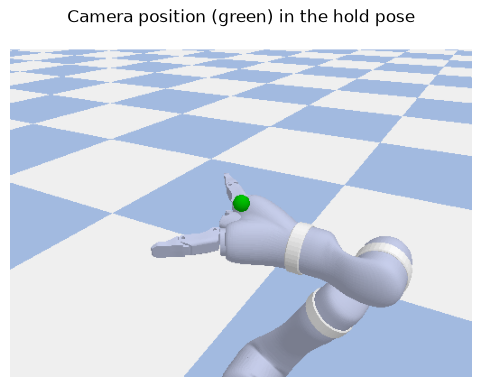

In [19]:
import os, subprocess, sys
CAM = Path('camera/wrist_fisheye_check.npz')
if not CAM.exists():   # renders with the RoboEnv Python (has PyBullet); about 1-2 minutes
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'wrist_camera.py', str(CAM)], check=True)
cam = np.load(CAM)
frames = pd.DataFrame(json.loads(str(cam['rows'])))
frames['dir_err_deg'] = np.abs((frames.est_dir_deg - frames.true_dir_deg + 180) % 360 - 180)
frames['dist_err_cm'] = 100 * (frames.est_dist_m - frames.true_dist_m).abs()
print(f'{len(frames)} frames from {frames.bearing.nunique()} bearings')
print('Detector vs ground truth:',
      f"missed {int(((~frames.found) & (frames.true_visible_px > 0)).sum())},",
      f"false detections {int((frames.found & (frames.true_visible_px == 0)).sum())},",
      f"red pixels that were not the dot {int(frames.false_red_px.sum())}")
plt.figure(figsize=(6, 4.5)); plt.imshow(cam['outside']); plt.axis('off')
plt.title('Camera position (green) in the hold pose'); plt.show()

### What the camera sees at the start, for every bearing

Title: bearing, and whether the dot was found. The robot hasn't moved yet.

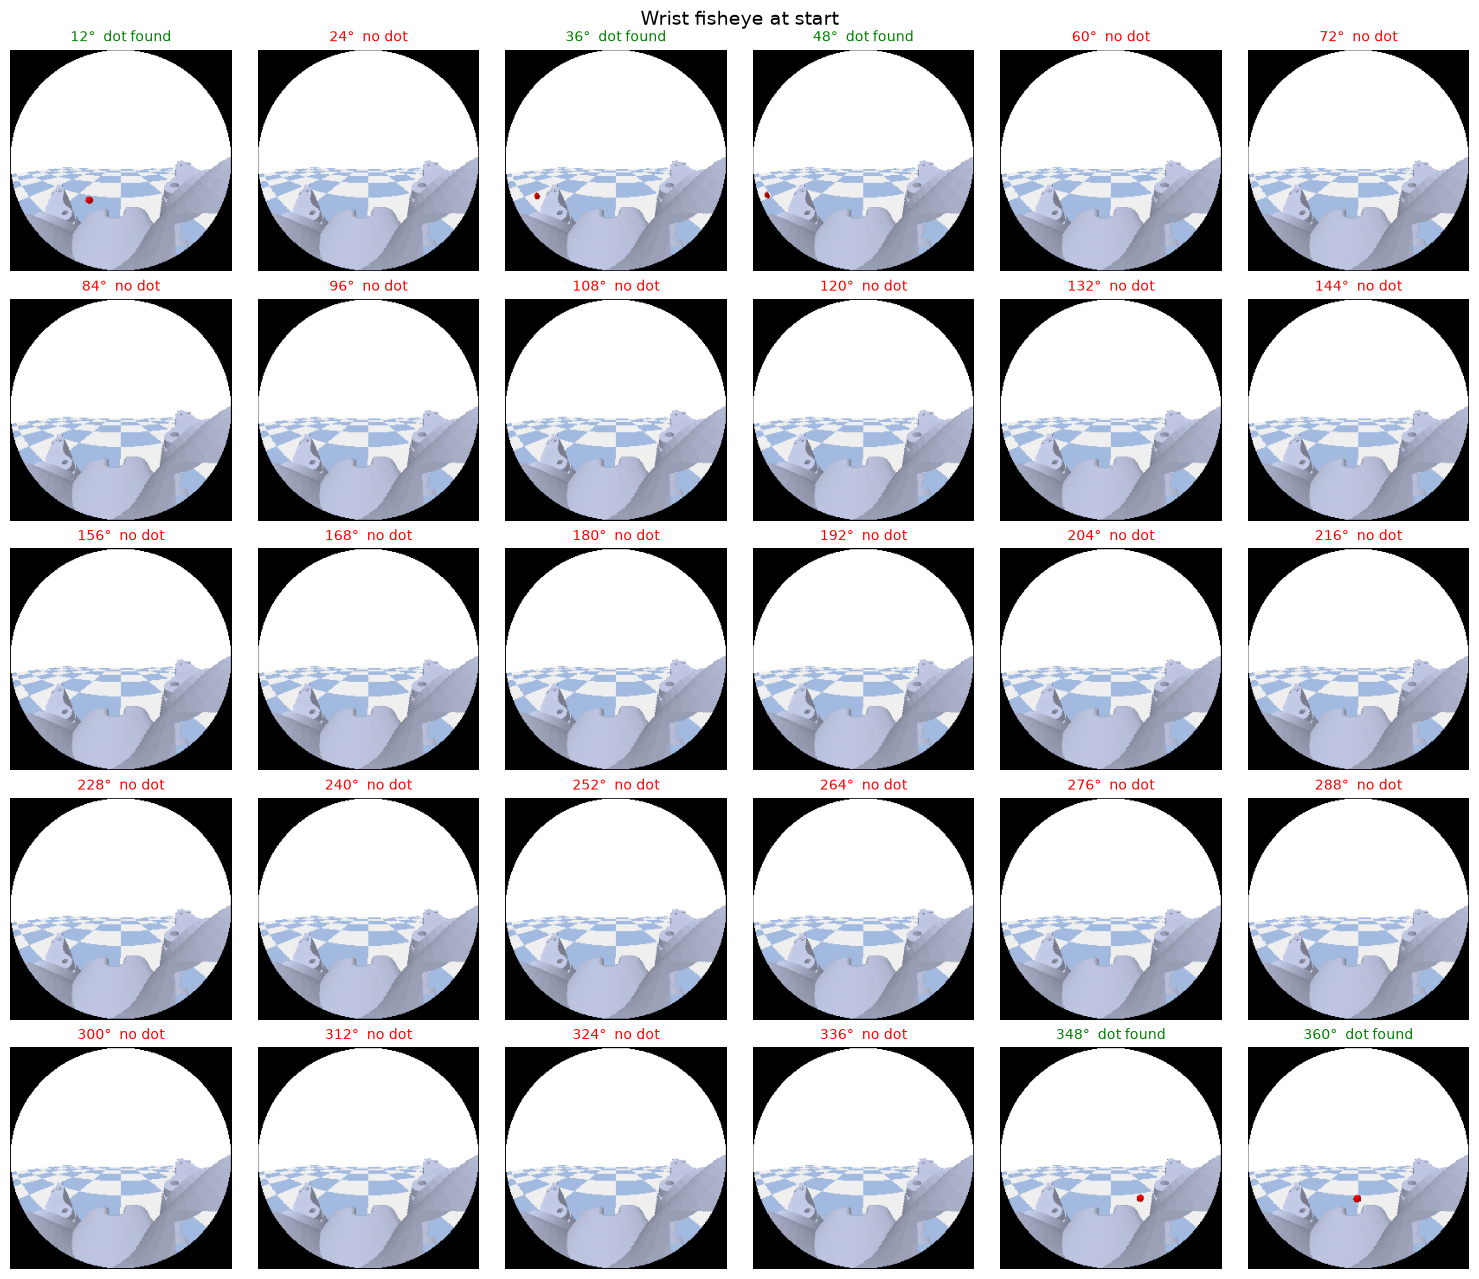

In [20]:
def grid(images, title):
    fig, axes = plt.subplots(5, 6, figsize=(15, 13))
    for ax, im, b in zip(axes.flat, images, cam['bearings']):
        f = frames[(frames.bearing == b)]
        row = f.iloc[0] if title == 'start' else f.iloc[-1]
        ax.imshow(im); ax.axis('off')
        ax.set_title(f"{b}°  {'dot found' if row.found else 'no dot'}", color='green' if row.found else 'red', fontsize=10)
    fig.suptitle(f'Wrist fisheye at {title}', fontsize=14); plt.tight_layout(); plt.show()
grid(cam['img_start'], 'start')

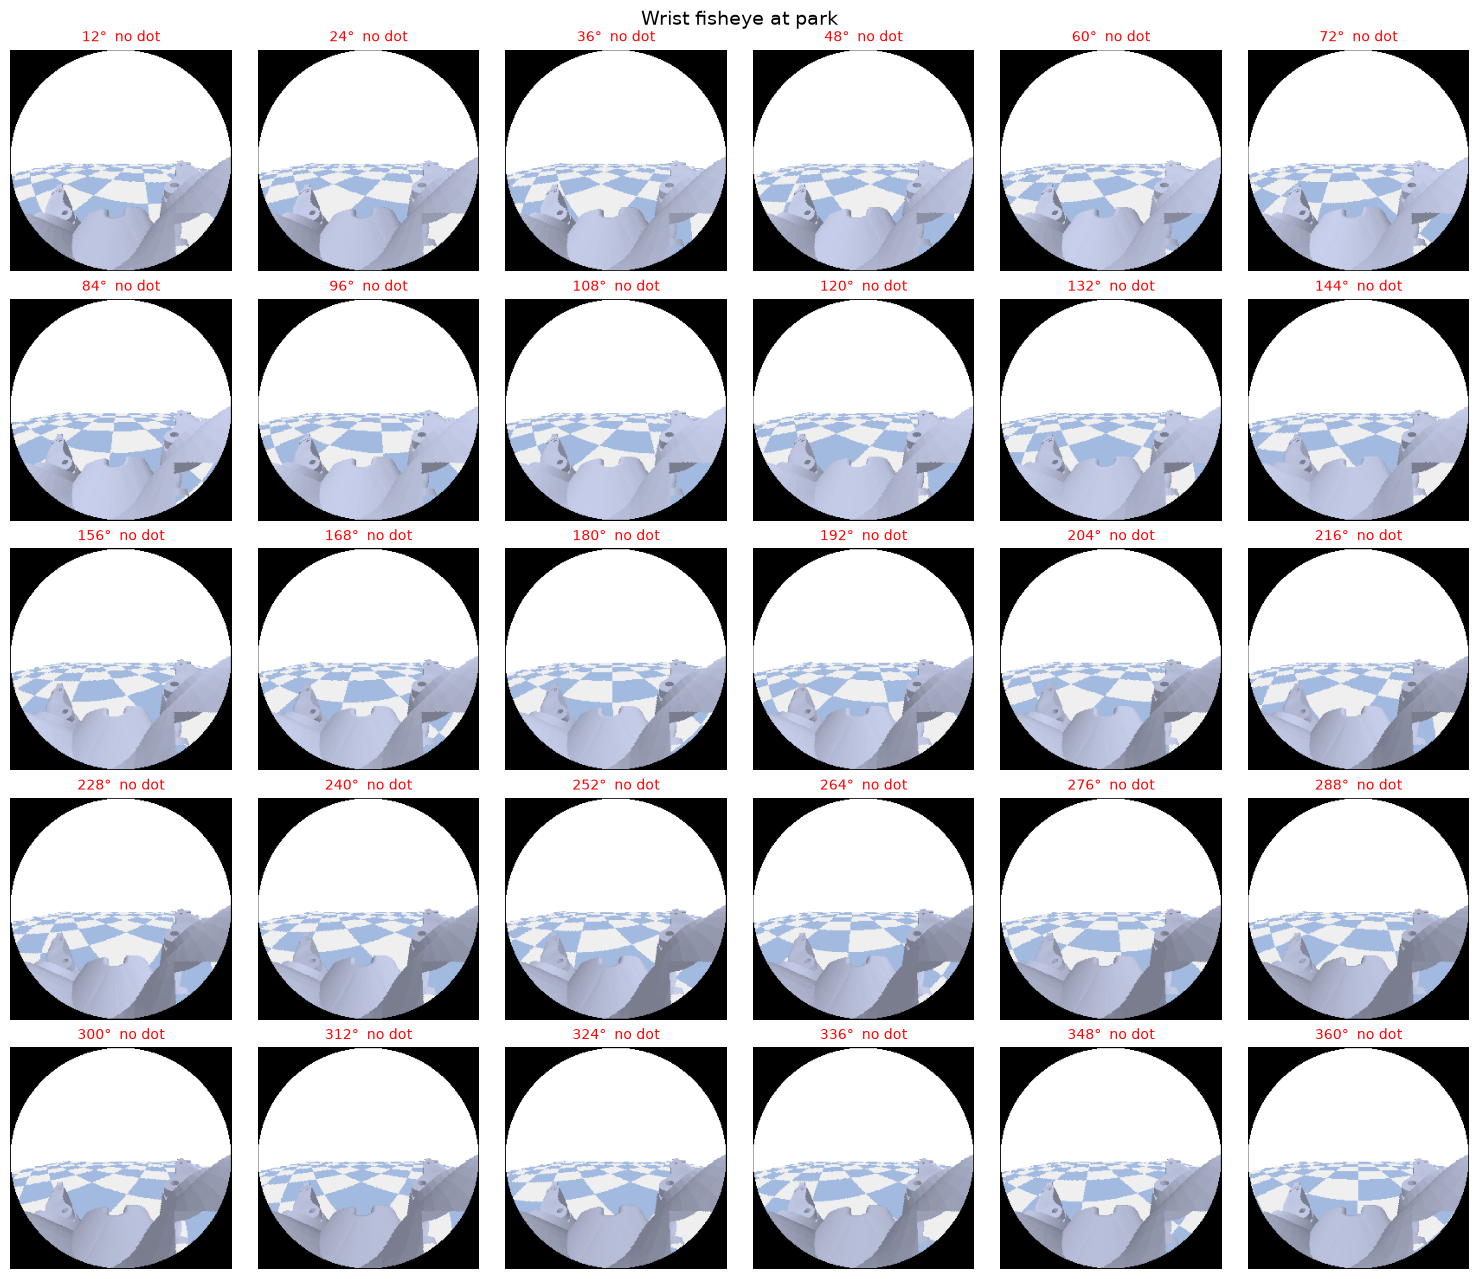

In [21]:
grid(cam['img_park'], 'park')

### Visibility and accuracy per bearing

`seen_at_start`: dot found in the first frame. `fraction_seen`: share of the drive's frames in which it was found. Errors are medians over frames where it was found, against the oracle.

In [22]:
per = frames.groupby('bearing').agg(seen_at_start=('found', 'first'), fraction_seen=('found', 'mean'),
    first_seen_s=('time_s', lambda t: t[frames.loc[t.index, 'found']].min()),
    dot_pixels=('dot_px', lambda s: s[s > 0].median()),
    direction_error_deg=('dir_err_deg', 'median'), distance_error_cm=('dist_err_cm', 'median'))
print(f"Seen at start: {int(per.seen_at_start.sum())} of {len(per)} bearings")
print(f"When seen: median direction error {frames.dir_err_deg.median():.2f}°, median distance error {frames.dist_err_cm.median():.2f} cm")
per.round(2)

Seen at start: 5 of 30 bearings
When seen: median direction error 0.14°, median distance error 0.85 cm


,seen_at_start,fraction_seen,first_seen_s,dot_pixels,direction_error_deg,distance_error_cm
bearing,,,,,,
12,True,0.53,0.0,64.0,0.10,0.78
24,False,0.47,0.2,63.0,0.13,0.77
36,True,0.57,0.0,51.5,0.16,1.00
48,True,0.62,0.0,59.0,0.14,0.85
60,False,0.54,0.4,60.0,0.18,0.88
72,False,0.52,0.6,61.5,0.16,0.84
84,False,0.52,0.6,54.0,0.22,0.85
96,False,0.48,0.8,55.0,0.17,0.94
108,False,0.50,1.0,56.0,0.19,0.97


### Reading the check

- **Accuracy when the dot is seen:** see the medians above. This is the camera + colour threshold + depth, with no training.
- **Start-of-run visibility:** with the arm in its hold pose, the hand and fingers sit below and around the camera. Bearings where the dot isn't found at the start were checked against the segmentation mask: the dot is genuinely out of view or hidden, not missed by the detector.
- **Consequence for the policy:** when the dot isn't visible at the start, the camera can't say which way to turn. That's the t = 0 problem again. It needs an explainable rule, for example "turn on the spot until the dot is seen", or memory (the occlusion experiment).

## Camera check: 180° fisheye RGB-D on the chassis nose (prow)

Same fisheye model, detector and checks as the hand camera (code: `prow_camera.py`). Only the mount changes:
- **on the chassis surface**, on the sloping nose in front of and slightly right of the arm base: `(0.29, -0.08, 0.36)` m in the base frame (surface at 0.33 m, plus 3 cm for the camera body);
- facing robot-forward, level;
- placed from a measured map of the chassis top (0.38 m behind the arm, sloping to 0.32 m at the front edge, x ≈ 0.32 m). The arm base occupies |y| < 0.045 m, so the camera sits just to its right.

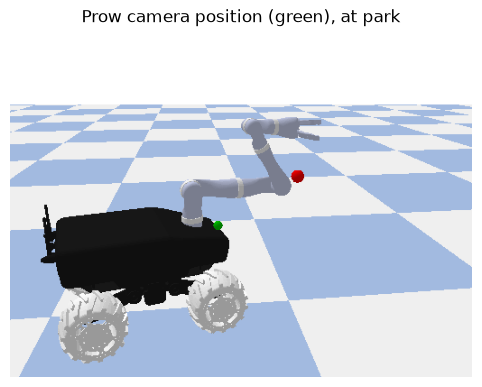

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0
Seen at start: 13 of 30 | seen at park: 12 of 30
When seen: median direction error 0.17°, median distance error 0.97 cm


In [23]:
import camera_check
if not Path('camera/prow_fisheye_check.npz').exists():
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'prow_camera.py',
                    'camera/prow_fisheye_check.npz'], check=True)
prow, prow_frames = camera_check.load('camera/prow_fisheye_check.npz')
plt.figure(figsize=(6, 4.5)); plt.imshow(prow['outside']); plt.axis('off'); plt.title('Prow camera position (green), at park'); plt.show()
prow_per = camera_check.summary(prow_frames)

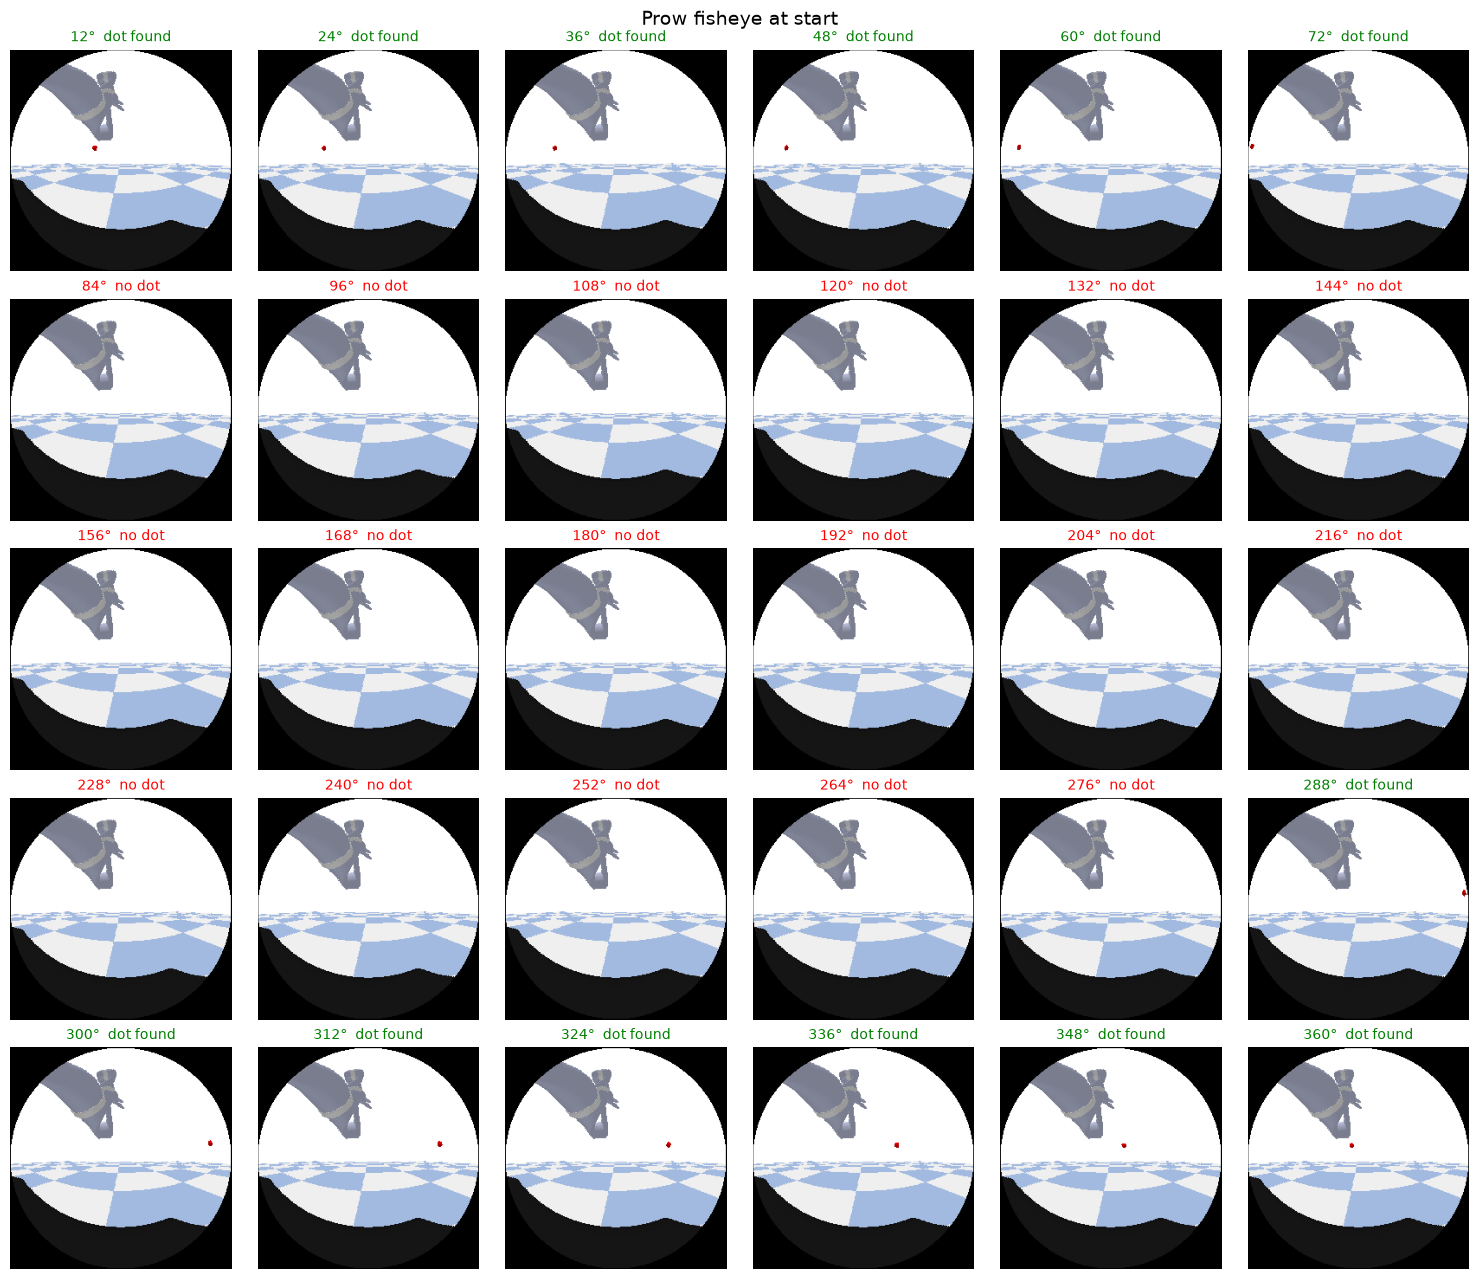

In [24]:
camera_check.grid(prow, prow_frames, 'start', 'Prow fisheye')

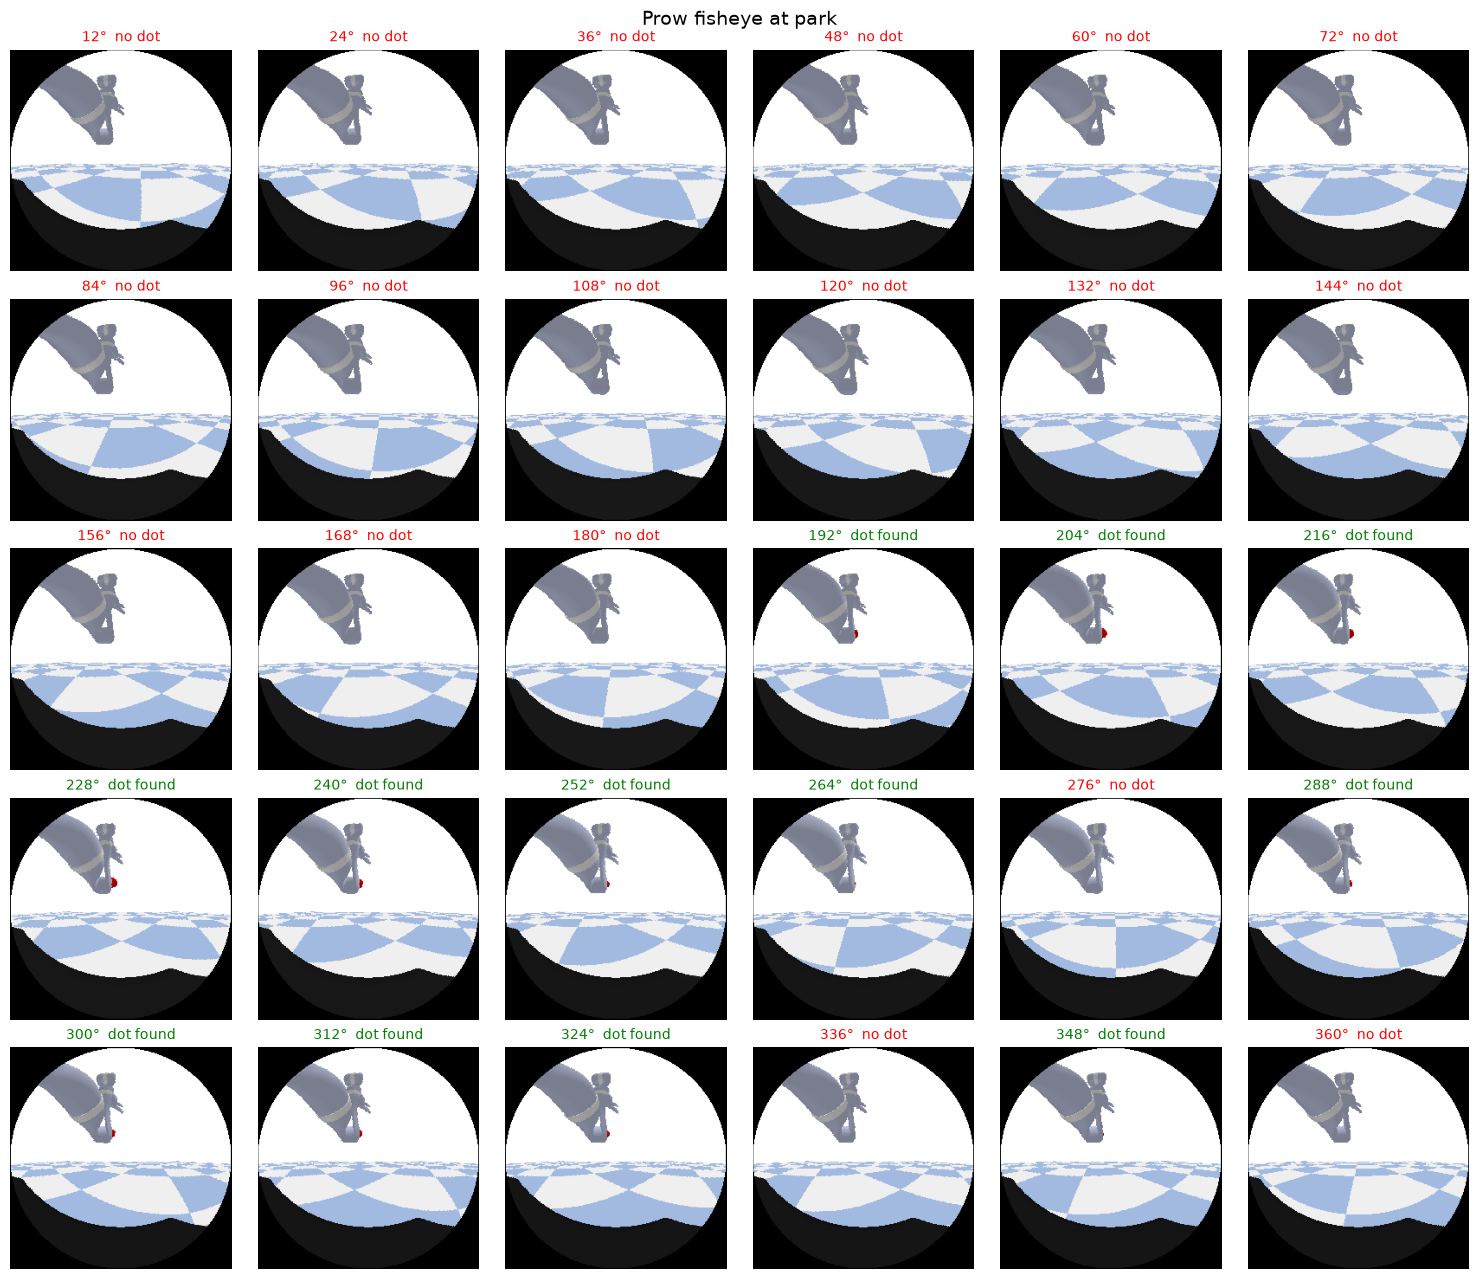

In [25]:
camera_check.grid(prow, prow_frames, 'park', 'Prow fisheye')

In [26]:
prow_per

,seen_at_start,seen_at_park,fraction_seen,dot_pixels,direction_error_deg,distance_error_cm
bearing,,,,,,
12,True,False,0.94,32.0,0.22,0.89
24,True,False,0.95,43.0,0.14,0.94
36,True,False,0.90,42.0,0.14,0.91
48,True,False,0.95,42.5,0.09,0.95
60,True,False,0.92,40.0,0.17,0.99
72,True,False,0.96,36.0,0.19,0.95
84,False,False,0.88,34.5,0.14,0.93
96,False,False,0.84,36.0,0.14,0.97
108,False,False,0.79,34.5,0.15,1.02


### Reading the prow check

| | Hand fisheye | Prow fisheye |
|---|---|---|
| Seen at start | 5 / 30 | 13 / 30 |
| Seen during the drive | about 30–60% of frames | **about 70–96% of frames** |
| Seen at park | 0 / 30 | 12 / 30 |
| Accuracy when seen | 0.14°, 0.9 cm | 0.17°, 1.0 cm |

- **During the drive, the prow camera sees the dot most of the time.** The arm is above it, so it rarely gets in the way.
- **Start:** bearings beyond about ±80° are outside the 180° view, so the robot can't tell which way to turn. It needs a rule or the tracker.
- **Park:** the dot finishes just behind the arm's forearm, at the edge of being hidden. Whether it's seen depends on a few degrees of final heading, which is why some bearings show it and others don't. A tracker carrying the last estimate covers this.
- **Detector:** no misses and no false detections against the segmentation ground truth.

## Camera check: 180° fisheye RGB-D on the front-right corner of the chassis

Same camera, detector and checks. Mount moved to the **front-right corner of the chassis top**: `(0.29, -0.13, 0.36)` m in the base frame, still facing forward and level. The chassis top reaches out to about |y| = 0.12 m at the front edge; beyond that, the front wheel is highest.

**Why:** the further the camera sits from the arm's centre line, the less the forearm should stand between it and the dot at park.

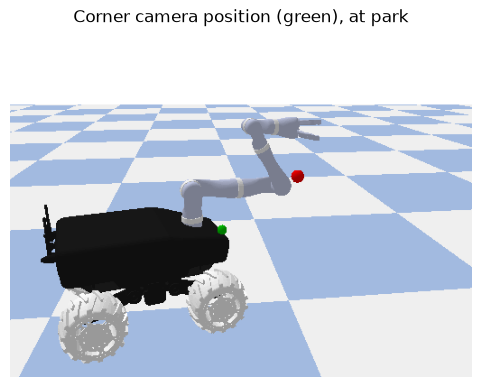

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0
Seen at start: 13 of 30 | seen at park: 19 of 30
When seen: median direction error 0.13°, median distance error 0.96 cm


In [27]:
import os
if not Path('camera/corner_fisheye_check.npz').exists():
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'prow_camera.py',
                    'camera/corner_fisheye_check.npz'], check=True, env=dict(os.environ, PROW_MOUNT='0.29,-0.13,0.36'))
corner, corner_frames = camera_check.load('camera/corner_fisheye_check.npz')
plt.figure(figsize=(6, 4.5)); plt.imshow(corner['outside']); plt.axis('off'); plt.title('Corner camera position (green), at park'); plt.show()
corner_per = camera_check.summary(corner_frames)

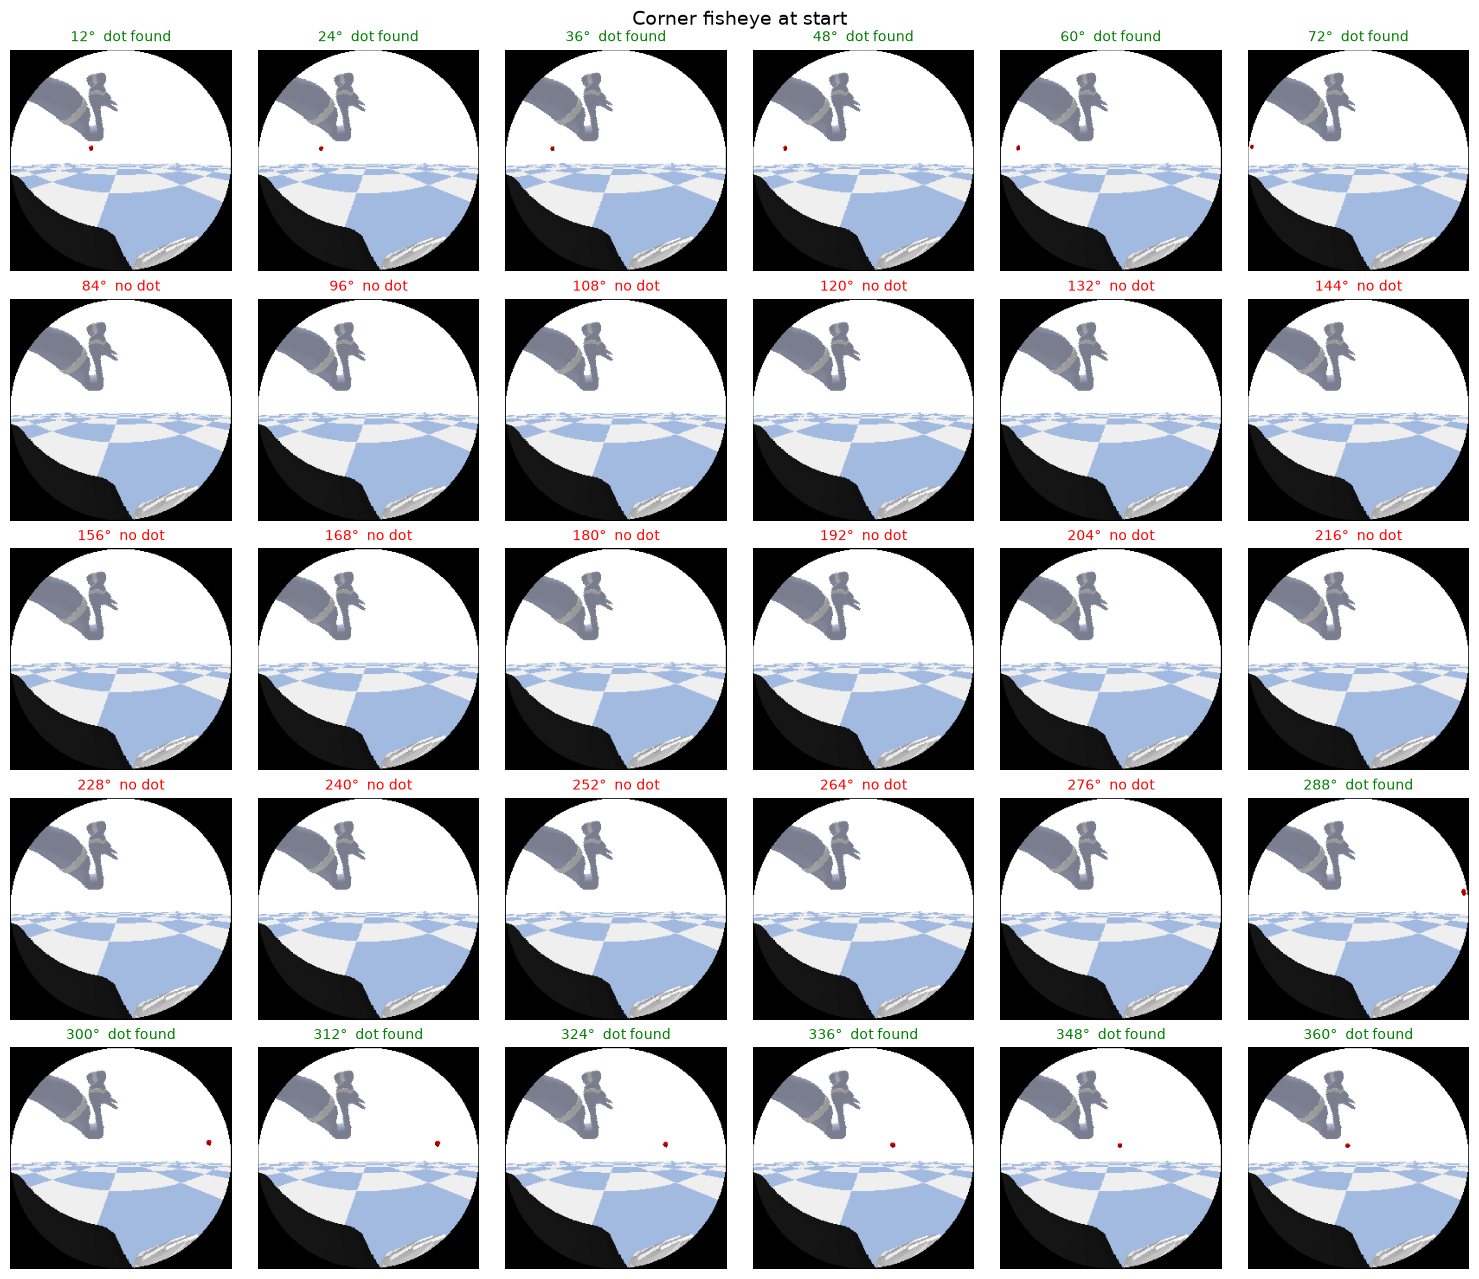

In [28]:
camera_check.grid(corner, corner_frames, 'start', 'Corner fisheye')

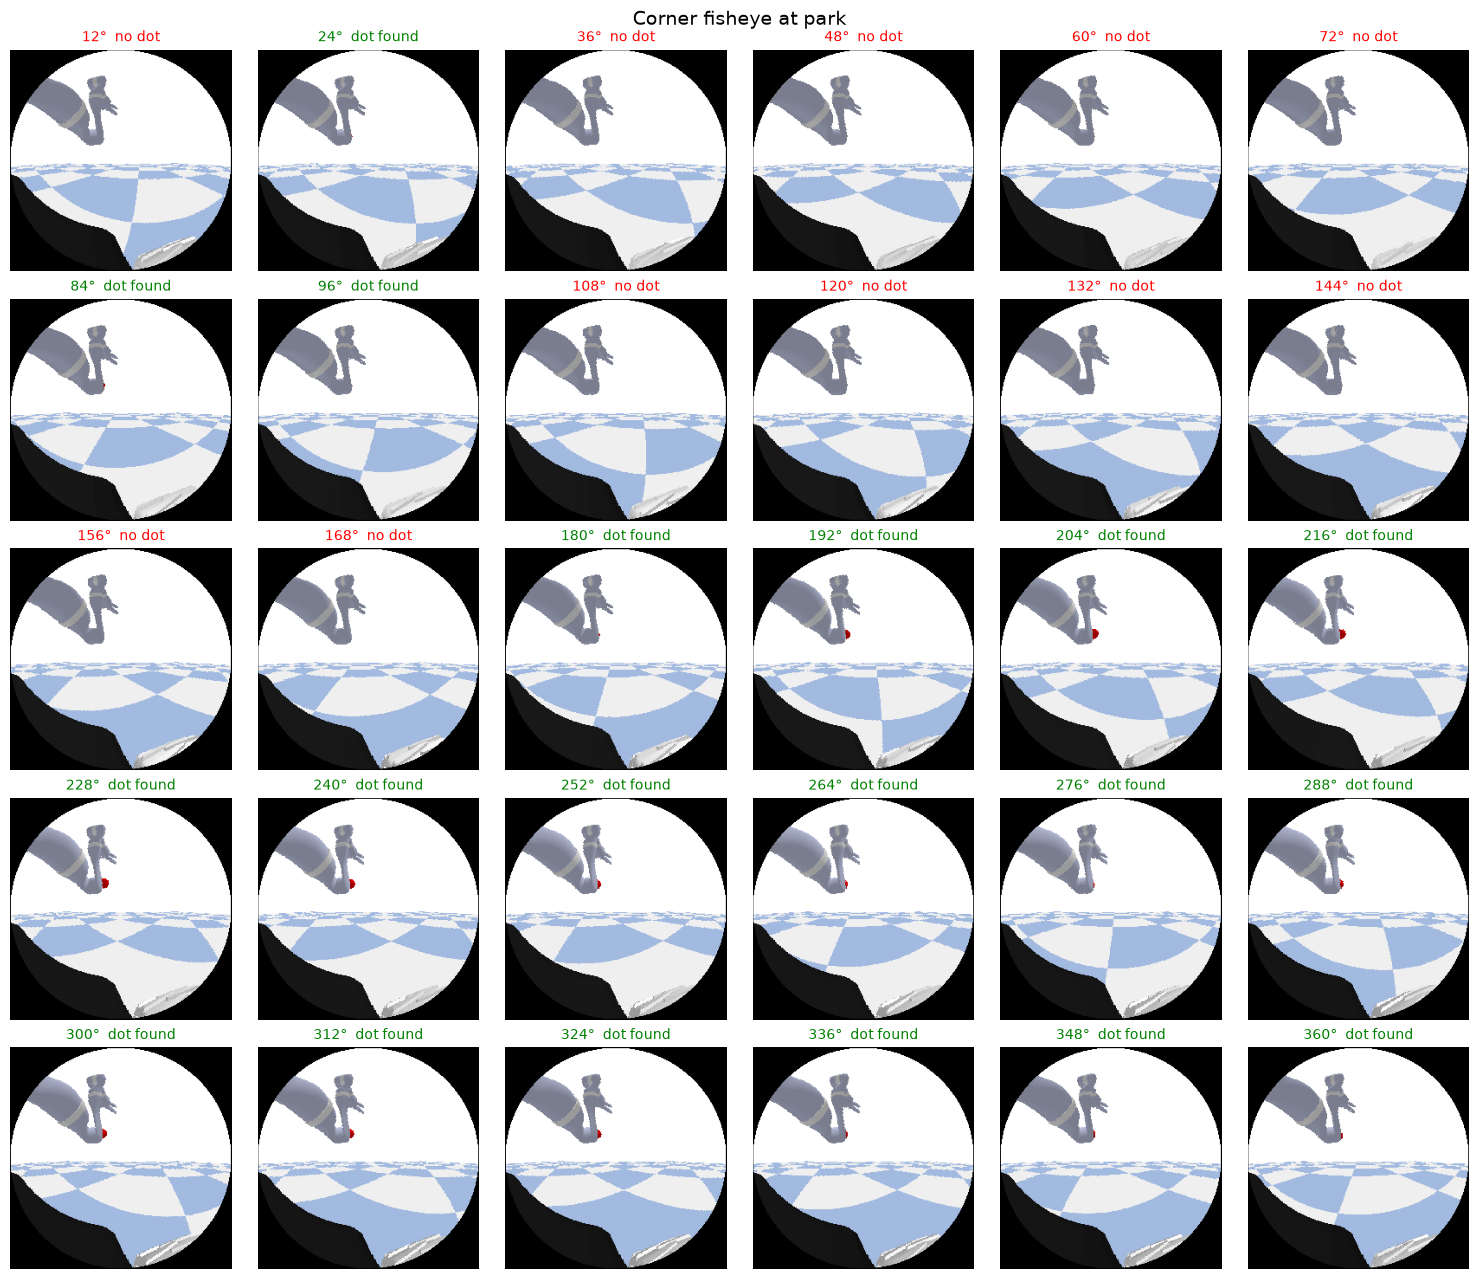

In [29]:
camera_check.grid(corner, corner_frames, 'park', 'Corner fisheye')

### Nose vs corner, per bearing

In [30]:
pd.concat({'nose': prow_per[['seen_at_start', 'seen_at_park', 'fraction_seen']],
           'corner': corner_per[['seen_at_start', 'seen_at_park', 'fraction_seen']]}, axis=1)

nose                                   corner               \
        seen_at_start seen_at_park fraction_seen seen_at_start seen_at_park   
bearing                                                                       
12               True        False          0.94          True        False   
24               True        False          0.95          True         True   
36               True        False          0.90          True        False   
48               True        False          0.95          True        False   
60               True        False          0.92          True        False   
72               True        False          0.96          True        False   
84              False        False          0.88         False         True   
96              False        False          0.84         False         True   
108             False        False          0.79         False        False   
120             False        False          0.80         False        False   
132             False        False          0.81         False        False   
144             False        False          0.77         False        False   
156             False        False          0.73         False        False   
168             False        False          0.73         False        False   
180             False        False          0.52         False         True   
192             False         True          0.70         False         True   
204             False         True          0.73         False         True   
216             False         True          0.78         False         True   
228             False         True          0.81         False         True   
240             False         True          0.83         False         True   
252             False         True          0.82         False         True   
264             False         True          0.84         False         True   
276             False        False          0.84         False         True   
288              True         True          0.96          True         True   
300              True         True          0.96          True         True   
312              True         True          0.95          True         True   
324              True         True          0.86          True         True   
336              True        False          0.74          True         True   
348              True         True          0.76          True         True   
360              True        False          0.91          True         True   

                       
        fraction_seen  
bearing                
12               0.94  
24               1.00  
36               0.95  
48               0.95  
60               0.92  
72               0.96  
84               0.92  
96               0.88  
108              0.79  
120              0.80  
132              0.81  
144              0.77  
156              0.76  
168              0.73  
180              0.58  
192              0.67  
204              0.70  
216              0.78  
228              0.77  
240              0.77  
252              0.75  
264              0.80  
276              0.80  
288              0.92  
300              0.92  
312              0.86  
324              0.81  
336              0.74  
348              0.76  
360              1.00

### Reading the corner check

| | Hand | Nose | **Corner** |
|---|---|---|---|
| Seen at start | 5 / 30 | 13 / 30 | 13 / 30 |
| Seen during the drive | about 30–60% | about 70–96% | about 60–100% |
| Seen at park | 0 / 30 | 12 / 30 | **19 / 30** |
| Accuracy when seen | 0.14°, 0.9 cm | 0.17°, 1.0 cm | 0.13°, 1.0 cm |

- Moving the camera 5 cm further out, from y = -0.08 to y = -0.13, raises park visibility from 12 to 19 of 30 bearings. The forearm blocks the dot less.
- The start is unchanged: dots beyond about ±80° are outside any forward 180° view.
- The front-right wheel now shows at the bottom edge of the image. It doesn't affect the dot, since it's below the horizon.
- The dot is still hidden at park for 11 bearings, 12°–72° and 108°–168°: the bearings where the robot turned left to reach the dot, so the tracker is still needed for the final moments.

## Camera models: the dot comes from the corner camera

`wheels+live_dot` was given the true dot position at every step. A real robot does not have that. These three models get the dot from the corner fisheye camera instead, and keep the same 12 wheel inputs.

At every step:

1. Render the corner fisheye from the robot's current pose.
2. Find the red pixels. Their centre gives a ray; the depth at those pixels gives a distance.
3. Use the fixed camera mount to turn that into the dot's position relative to the robot.
4. A tracker holds that position. When the dot is seen, it is replaced. When the dot is hidden, it is moved using the wheel encoders.
5. The network gets the tracker's distance and the sin and cos of its direction. Until the dot is first seen, these are 0, 0, 0.

| Model | Dot inputs | PARK output |
|---|---|---|
| `camera+flag` | distance, sin, cos, visible flag (1 when the camera sees the dot in this frame) | PARK yes/no |
| `camera+flag+time_to_park` | distance, sin, cos, visible flag | seconds until the expert would park; PARK at 0.25 s or less |
| `camera+time_to_park` | distance, sin, cos | seconds until the expert would park; PARK at 0.35 s or less |

The network and training are the same as before: 2×16 ReLU, 4 wheel outputs, 21 training runs, Adam, lr 0.01, 300 epochs, seed 7. `camera_features.py` computes the camera inputs for the training runs from the expert's recorded poses and saves them in `camera_features/`.

In [31]:
CAM = Path('camera_features')
for e in rows:
    if e['split'] != 'holdout':
        e['camera'] = np.load(CAM / f"camera_{e['bearing']}.npy")      # distance, sin, cos, visible
        assert len(e['camera']) == len(e['x'])

CLIP, THRESH = 3.0, 0.25          # time to park is clipped at 3 s and scaled to 0..1
CAMERA_MODELS = {                  # name: (dot input columns, PARK output)
    'camera+flag':              ([0, 1, 2, 3], 'park'),
    'camera+flag+time_to_park': ([0, 1, 2, 3], 'time_to_park'),
    'camera+time_to_park':      ([0, 1, 2],    'time_to_park'),
}

def camera_inputs(e, cols):
    return np.c_[e['x'][:, WHEEL], e['camera'][:, cols]].astype(np.float32)

def time_to_park(e):              # one PARK row per run, the last one
    t = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == e['bearing'])['archive'])['time_s']
    return (np.minimum(t[-1] - t, CLIP) / CLIP).astype(np.float32)

class CameraPolicy(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
        self.wheels = nn.Linear(16, 4)
        self.park = nn.Linear(16, 1)          # PARK logit, or scaled time to park
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h), self.park(h).squeeze(1)

def camera_data(eps, cols, head):
    X = torch.from_numpy(np.concatenate([camera_inputs(e, cols) for e in eps]))
    W = torch.from_numpy(np.concatenate([e['wheels'] for e in eps]).astype(np.float32))
    w = torch.from_numpy(np.concatenate([np.full(len(e['x']), 1 / (len(e['x']) * len(eps))) for e in eps]).astype(np.float32))
    if head == 'park':
        P = torch.from_numpy(np.concatenate([e['park'] for e in eps]).astype(np.float32))
    else:
        P = torch.from_numpy(np.concatenate([time_to_park(e) for e in eps]))
    return X, W, P, w

def camera_losses(model, data, head, pos_weight):
    X, W, P, w = data
    pw, pp = model(X)
    wheel_mse = (w * ((pw - W) ** 2).mean(1)).sum()
    if head == 'park':
        park_loss = F.binary_cross_entropy_with_logits(pp, P, pos_weight=pos_weight)       # weighted by PARK_WEIGHT in the total
    else:
        park_loss = (w * (pp - P) ** 2).sum()                                               # each run counts equally, weight 1
    return wheel_mse, park_loss

camera_history = []
def train_camera_model(name, cols, head):
    torch.manual_seed(SEED)
    tr, te = camera_data(train, cols, head), camera_data(test, cols, head)
    pos_weight = (len(tr[2]) - tr[2].sum()) / tr[2].sum() if head == 'park' else None    # from training data only
    model = CameraPolicy(tr[0].shape[1]); opt = torch.optim.Adam(model.parameters(), lr=LR)
    for epoch in range(EPOCHS + 1):
        wheel_mse, park_loss = camera_losses(model, tr, head, pos_weight)
        with torch.no_grad():
            te_wheel, te_park = camera_losses(model, te, head, pos_weight)                   # test is only watched, never trained on
        camera_history.append(dict(model=name, epoch=epoch, train_wheel_mse=wheel_mse.item(), test_wheel_mse=te_wheel.item(),
                                   train_park_loss=park_loss.item(), test_park_loss=te_park.item()))
        if epoch < EPOCHS:
            total = wheel_mse + (PARK_WEIGHT * park_loss if head == 'park' else park_loss)
            opt.zero_grad(); total.backward(); opt.step()
    return model

camera_models = {}
for name, (cols, head) in CAMERA_MODELS.items():
    camera_models[name] = m = train_camera_model(name, cols, head)
    sd = {k: v.detach().numpy() for k, v in m.state_dict().items()}
    if head == 'time_to_park':
        sd['ttp_clip'], sd['ttp_thresh'] = np.float32(CLIP), np.float32(THRESH)
    # Compare with the saved network that was tested.
    tested = np.load({'camera+flag': 'models/camera_flag.npz', 'camera+flag+time_to_park': 'models/camera_flag_ttp.npz',
                      'camera+time_to_park': 'models/camera_ttp_noflag.npz'}[name])
    diff = max(float(np.abs(sd[k] - tested[k]).max()) for k in tested.files)
    print(f'{name:26s} inputs={len(WHEEL) + len(cols)}  largest weight difference vs the tested model: {diff:.1e}')
# Small differences are floating-point rounding. The tests below use the saved networks in models/.
camera_history = pd.DataFrame(camera_history)

camera+flag                inputs=16  largest weight difference vs the tested model: 7.2e-07


camera+flag+time_to_park   inputs=16  largest weight difference vs the tested model: 6.7e-04


camera+time_to_park        inputs=15  largest weight difference vs the tested model: 2.7e-04


### Training curves

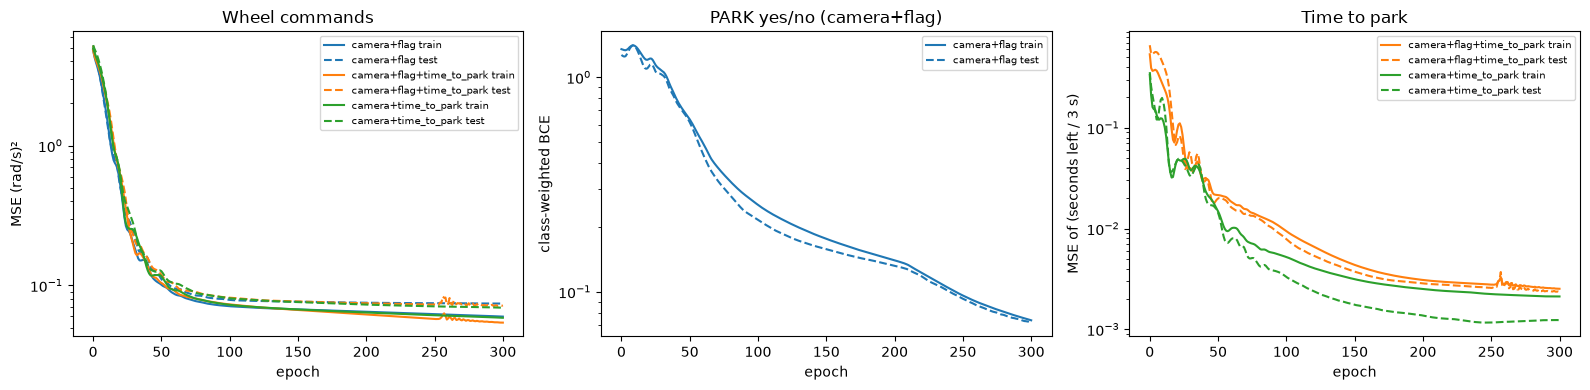

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in camera_history.groupby('model', sort=False):
    line, = ax[0].plot(h.epoch, h.train_wheel_mse, label=f'{name} train')
    ax[0].plot(h.epoch, h.test_wheel_mse, '--', color=line.get_color(), label=f'{name} test')
    a = ax[1] if CAMERA_MODELS[name][1] == 'park' else ax[2]
    a.plot(h.epoch, h.train_park_loss, color=line.get_color(), label=f'{name} train')
    a.plot(h.epoch, h.test_park_loss, '--', color=line.get_color(), label=f'{name} test')
ax[0].set(title='Wheel commands', ylabel='MSE (rad/s)²')
ax[1].set(title='PARK yes/no (camera+flag)', ylabel='class-weighted BCE')
ax[2].set(title='Time to park', ylabel='MSE of (seconds left / 3 s)')
for a in ax:
    a.set(xlabel='epoch', yscale='log'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
# Solid: 21 training runs. Dashed: 4 test runs, watched only. Training always stops at 300 epochs.

**Model to build from:** `camera+flag+time_to_park` (`models/camera_flag_ttp.npz`). PARK at 0.25 s or less. Parked 16 of 25.

### Testing

Each model drives the robot in the fast simulator (`sensor_parking`), with the camera steps above running every 1/30 s. There are 25 bearings: the 21 training runs and the 4 test runs. The 5 holdout bearings are not used. Each run is allowed the expert's park time plus 3 s, and its final position is compared with the expert's. `wheels+live_dot`, which sees the true dot, is shown for comparison.

In [33]:
ref = json.loads(Path('expert_reference.json').read_text())['bearings']
RESULTS = {'camera+flag': 'camera_flag', 'camera+flag+time_to_park': 'camera_flag_ttp',
           'camera+time_to_park': 'camera_ttp_noflag_0.35s'}   # PARK at 0.35 s or less

def angle(a):
    return float(np.rad2deg(abs((a + np.pi) % (2 * np.pi) - np.pi)))

tests = []
for name, folder in RESULTS.items():
    for b, x in ref.items():
        run = json.loads(Path(f'camera_loop/{folder}/run_{b}.json').read_text()); log = run['log']
        park_t = next((l['t'] for l in log if l['park_prob'] >= 0.5), None)
        tests.append(dict(model=name, bearing=int(b), split=x['split'], seen_at_start=log[0]['visible'], parked=run['parked'],
                          final_error_cm=100 * np.hypot(*np.subtract(run['final_base'], x['final_base_xy'])),
                          final_heading_error_deg=angle(run['final_yaw'] - x['final_yaw']),
                          park_time_vs_expert_s=None if park_t is None else park_t - x['park_time_s'],
                          dot_distance_error_cm=100 * np.mean([abs(l['est_dist'] - l['true_dist']) for l in log if l['visible']] or [np.nan])))
tests = pd.DataFrame(tests)
true_dot = closed[closed.model == 'wheels+live_dot'].set_index('bearing_deg')
tests['true_dot_parked'] = tests.bearing.map(true_dot.parked)

def summary(g):
    return pd.Series({'runs': len(g), 'parked': int(g.parked.sum()), 'true-dot model parked': int(g.true_dot_parked.sum()),
                      'median final error (cm)': round(g.final_error_cm.median(), 1)})
by = {'all': tests, 'dot seen at start': tests[tests.seen_at_start], 'dot not seen at start': tests[~tests.seen_at_start]}
pd.concat({k: v.groupby('model', sort=False).apply(summary) for k, v in by.items()}).unstack(0).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0, sort_remaining=False)

all                               \
                          runs parked true-dot model parked   
model                                                         
camera+flag               25.0   17.0                  23.0   
camera+flag+time_to_park  25.0   16.0                  23.0   
camera+time_to_park       25.0    6.0                  23.0   

                                                 dot not seen at start         \
                         median final error (cm)                  runs parked   
model                                                                           
camera+flag                                 16.7                  14.0   10.0   
camera+flag+time_to_park                    14.5                  14.0    9.0   
camera+time_to_park                         44.8                  14.0    0.0   

                                                                        \
                         true-dot model parked median final error (cm)   
model                                                                    
camera+flag                               12.0                    15.1   
camera+flag+time_to_park                  12.0                    14.9   
camera+time_to_park                       12.0                    50.6   

                         dot seen at start                               \
                                      runs parked true-dot model parked   
model                                                                     
camera+flag                           11.0    7.0                  11.0   
camera+flag+time_to_park              11.0    7.0                  11.0   
camera+time_to_park                   11.0    6.0                  11.0   

                                                  
                         median final error (cm)  
model                                             
camera+flag                                 22.4  
camera+flag+time_to_park                    14.5  
camera+time_to_park                         19.9

### Every bearing: parked or not

In [34]:
tests.pivot_table(index=['split', 'bearing', 'seen_at_start'], columns='model', values='parked', aggfunc='first', sort=False)\
     .reindex(columns=list(RESULTS)).join(true_dot.parked.rename('wheels+live_dot (true dot)'), on='bearing')

camera+flag  camera+flag+time_to_park  \
split bearing seen_at_start                                          
train 12      True                 False                      True   
      36      True                  True                     False   
      60      True                 False                     False   
      72      True                 False                     False   
      84      False                False                     False   
      120     False                False                     False   
      156     False                 True                     False   
      168     False                 True                      True   
      180     False                 True                      True   
      192     False                 True                      True   
      216     False                 True                      True   
      228     False                 True                      True   
      240     False                 True                      True   
      252     False                 True                      True   
      264     False                 True                      True   
      288     True                  True                      True   
      300     True                  True                      True   
      312     True                  True                      True   
      336     True                  True                      True   
      348     True                  True                      True   
      360     True                 False                     False   
test  24      True                  True                      True   
      108     False                False                     False   
      132     False                False                     False   
      204     False                 True                      True   

                             camera+time_to_park  wheels+live_dot (true dot)  
split bearing seen_at_start                                                   
train 12      True                          True                        True  
      36      True                         False                        True  
      60      True                         False                        True  
      72      True                         False                        True  
      84      False                        False                        True  
      120     False                        False                        True  
      156     False                        False                       False  
      168     False                        False                       False  
      180     False                        False                        True  
      192     False                        False                        True  
      216     False                        False                        True  
      228     False                        False                        True  
      240     False                        False                        True  
      252     False                        False                        True  
      264     False                        False                        True  
      288     True                         False                        True  
      300     True                          True                        True  
      312     True                         False                        True  
      336     True                          True                        True  
      348     True                          True                        True  
      360     True                          True                        True  
test  24      True                          True                        True  
      108     False                        False                        True  
      132     False                        False                        True  
      204     False                        False                        True

### Every bearing: final position error (cm) and camera distance error when the dot is seen (cm)

In [35]:
pd.concat({'final error (cm)': tests.pivot_table(index=['split', 'bearing'], columns='model', values='final_error_cm', sort=False),
           'camera distance error (cm)': tests.pivot_table(index=['split', 'bearing'], columns='model', values='dot_distance_error_cm', sort=False)},
          axis=1).round(1)

final error (cm)                                               \
model              camera+flag camera+flag+time_to_park camera+time_to_park   
split bearing                                                                 
train 12                   9.9                      2.9                 6.7   
      36                  18.3                     21.7                23.4   
      60                  34.8                      4.4                24.2   
      72                  36.2                     30.9                23.5   
      84                  24.7                     42.2                49.1   
      120                 24.1                     22.3                49.2   
      156                 28.5                     25.1                55.2   
      168                 15.5                     18.3                53.5   
      180                 12.4                      9.9                49.6   
      192                  9.4                     10.8                53.5   
      216                 12.2                     12.3                53.1   
      228                 14.9                     12.3                50.1   
      240                 12.7                     16.2                48.5   
      252                 14.2                     13.7                44.8   
      264                 16.7                     12.2                40.7   
      288                 22.4                     14.7                36.7   
      300                 29.0                     14.5                18.0   
      312                 24.0                     14.9                31.8   
      336                 22.4                     11.9                19.2   
      348                 19.1                     12.0                19.9   
      360                  2.5                     20.1                 9.7   
test  24                  13.9                      3.1                 8.1   
      108                 15.3                     20.8                51.4   
      132                 27.5                     22.4                51.1   
      204                 11.3                     11.2                54.2   

              camera distance error (cm)                           \
model                        camera+flag camera+flag+time_to_park   
split bearing                                                       
train 12                             0.9                      0.8   
      36                             0.8                      0.9   
      60                             1.0                      0.9   
      72                             1.0                      0.9   
      84                             1.0                      1.1   
      120                            1.0                      0.9   
      156                            1.0                      0.9   
      168                            1.0                      0.9   
      180                            1.0                      0.9   
      192                            1.0                      1.0   
      216                            1.0                      0.9   
      228                            0.8                      0.9   
      240                            0.8                      0.9   
      252                            0.9                      0.9   
      264                            0.9                      0.9   
      288                            1.0                      0.9   
      300                            1.1                      0.9   
      312                            1.0                      0.9   
      336                            1.0                      0.8   
      348                            1.0                      0.8   
      360                            0.9                      0.8   
test  24                             0.8                      0.8   
      108                            0.9                      1.0   
      1

## Test metrics, plotted

Every count is out of 25 bearings: 21 training runs and 4 test runs. Worst cases come first. `camera+flag+time_to_park` is the model to build from.

In [36]:
runs = {}                         # (model, bearing) -> saved test run
for name, folder in RESULTS.items():
    for b in ref:
        runs[name, int(b)] = json.loads(Path(f'camera_loop/{folder}/run_{b}.json').read_text())
# Expert paths, for drawing only (from the verified expert replay).
expert_path = {r['bearing_deg']: np.array([f['base'][:2] for f in r['expert']['frames']])
               for r in json.loads(Path('closed_loop_native/result_wheels_live_dot.json').read_text())['runs']}
MAIN = 'camera+flag+time_to_park'
COLORS = dict(zip(list(RESULTS) + ['wheels+live_dot (true dot)'], ['tab:blue', 'tab:orange', 'tab:green', 'grey']))
bearings = sorted(int(b) for b in ref)

### 1. Which bearings park? (green parked, red not, grey background: dot not visible at the start)

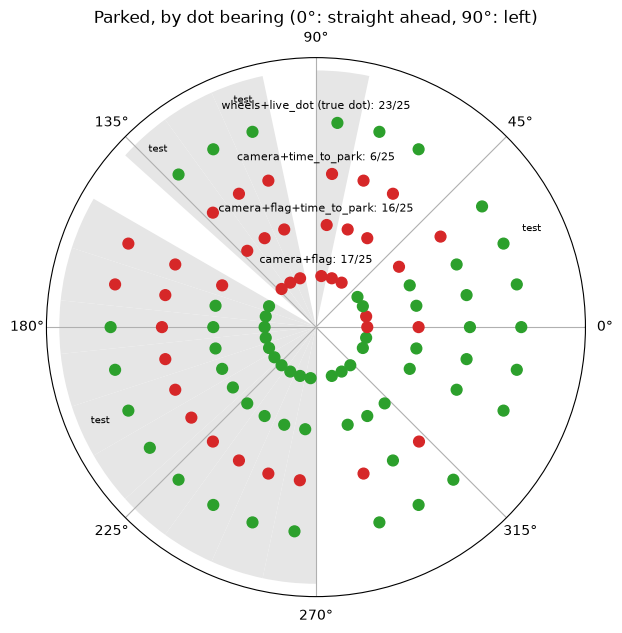

In [37]:
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(projection='polar')
names = list(RESULTS) + ['wheels+live_dot (true dot)']
unseen = [b for b in bearings if not runs[MAIN, b]['log'][0]['visible']]
for b in unseen:
    ax.bar(np.deg2rad(b), len(names) + 1, width=np.deg2rad(12), color='0.9', zorder=0)
for k, name in enumerate(names):
    parked = [true_dot.parked[b] if 'true dot' in name else runs[name, b]['parked'] for b in bearings]
    ax.scatter(np.deg2rad(bearings), np.full(len(bearings), k + 1), c=['tab:green' if p else 'tab:red' for p in parked], s=60, zorder=2)
    ax.text(np.deg2rad(90), k + 1.25, f'{name}: {sum(parked)}/25', fontsize=8, ha='center')
ax.set_yticks([]); ax.set_theta_zero_location('E'); ax.set_title('Parked, by dot bearing (0°: straight ahead, 90°: left)')
for b in [b for b in bearings if ref[str(b)]['split'] == 'test']:
    ax.annotate('test', (np.deg2rad(b), len(names) + 0.6), fontsize=7, ha='center')
plt.show()

### 2. Final position error, worst first (bars: model to build from; markers: the others)

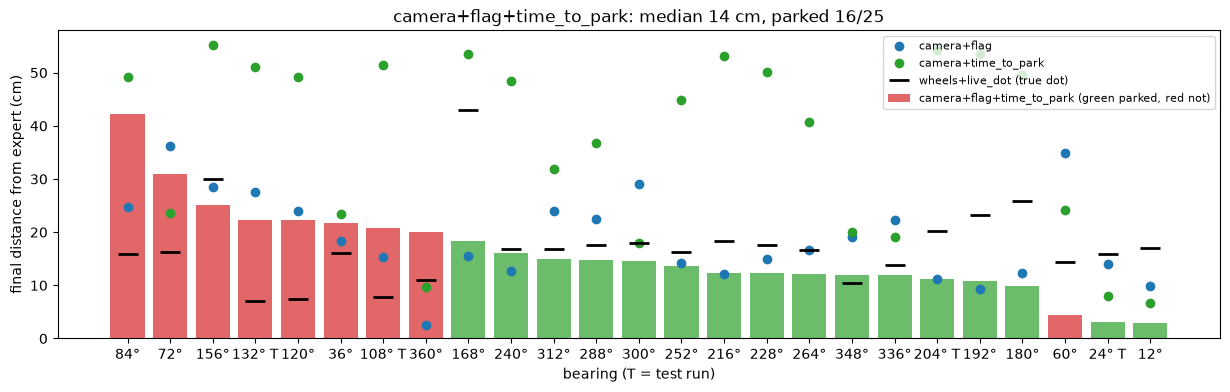

In [38]:
order = tests[tests.model == MAIN].sort_values('final_error_cm', ascending=False)
fig, ax = plt.subplots(figsize=(15, 4))
x = np.arange(len(order))
ax.bar(x, order.final_error_cm, color=['tab:green' if p else 'tab:red' for p in order.parked], alpha=0.7, label=f'{MAIN} (green parked, red not)')
for name in RESULTS:
    if name != MAIN:
        e = tests[tests.model == name].set_index('bearing').loc[order.bearing, 'final_error_cm']
        ax.plot(x, e.values, 'o', color=COLORS[name], label=name)
ax.plot(x, true_dot.loc[order.bearing, 'final_xy_error_m'].values * 100, 'k_', ms=14, mew=2, label='wheels+live_dot (true dot)')
ax.set_xticks(x, [f"{b}°{' T' if s == 'test' else ''}" for b, s in zip(order.bearing, order.split)])
ax.set(ylabel='final distance from expert (cm)', xlabel='bearing (T = test run)',
       title=f'{MAIN}: median {order.final_error_cm.median():.0f} cm, parked {int(order.parked.sum())}/25')
ax.legend(fontsize=8); plt.show()

### 3. Heading error and park timing, per bearing

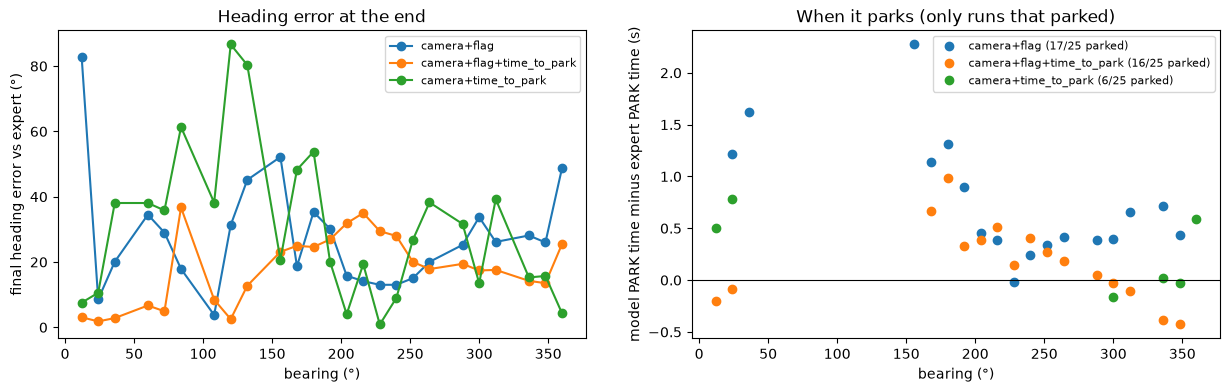

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for name in RESULTS:
    t = tests[tests.model == name].sort_values('bearing')
    ax[0].plot(t.bearing, t.final_heading_error_deg, 'o-', color=COLORS[name], label=name)
    p = t.dropna(subset=['park_time_vs_expert_s'])
    ax[1].plot(p.bearing, p.park_time_vs_expert_s, 'o', color=COLORS[name], label=f'{name} ({len(p)}/25 parked)')
ax[0].set(xlabel='bearing (°)', ylabel='final heading error vs expert (°)', title='Heading error at the end')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set(xlabel='bearing (°)', ylabel='model PARK time minus expert PARK time (s)', title='When it parks (only runs that parked)')
for a in ax: a.legend(fontsize=8)
plt.show()

### 4. Paths from above: the 4 worst and 2 best bearings for the model to build from

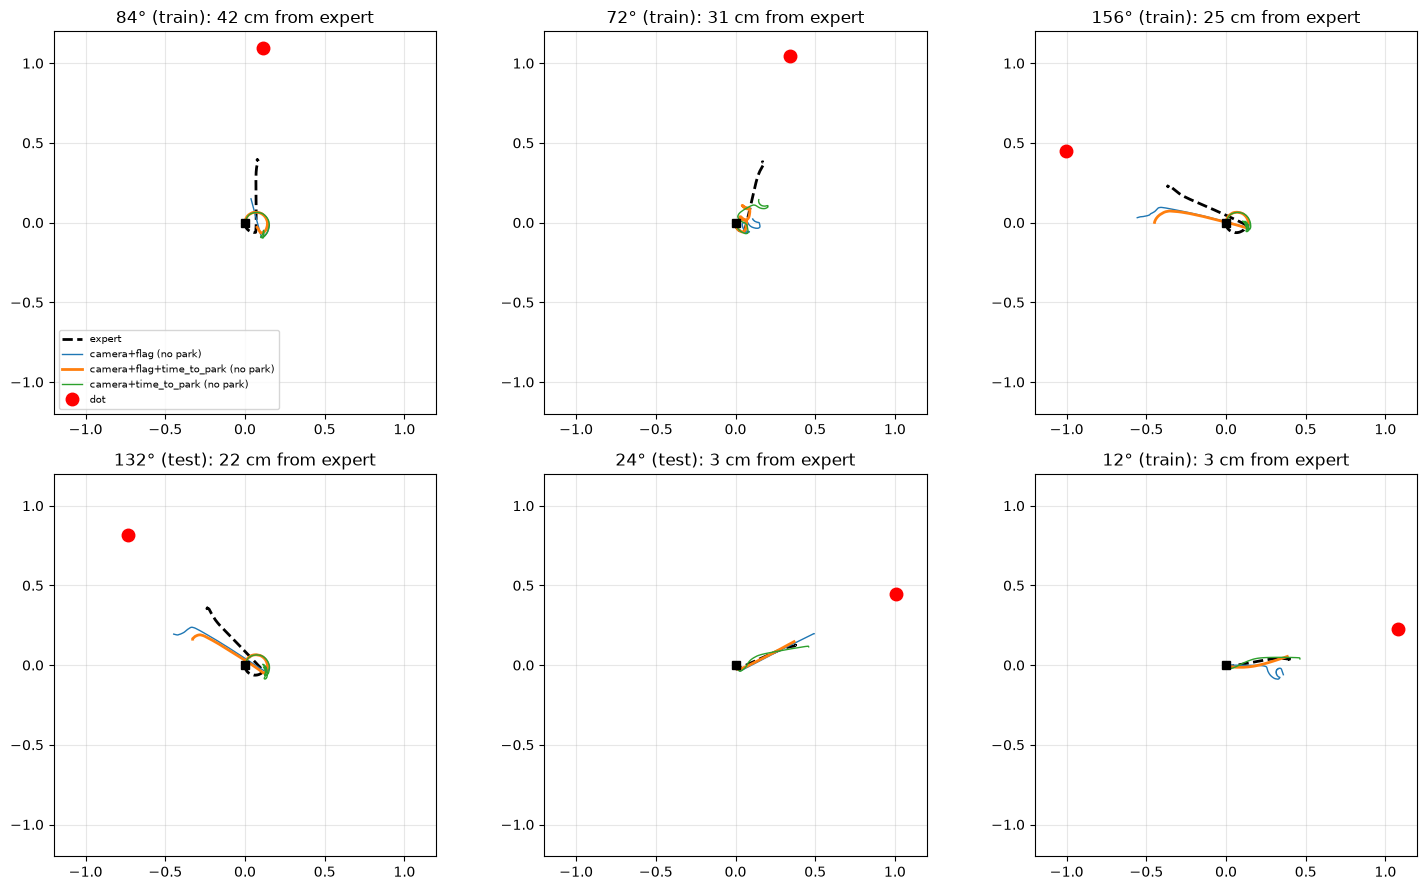

In [40]:
pick = list(order.bearing[:4]) + list(order.bearing[-2:])
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, b in zip(ax.ravel(), pick):
    e = expert_path[b]; a.plot(e[:, 0], e[:, 1], 'k--', lw=2, label='expert')
    for name in RESULTS:
        m = np.array([l['base'] for l in runs[name, b]['log']])
        a.plot(m[:, 0], m[:, 1], color=COLORS[name], lw=2 if name == MAIN else 1, label=f"{name} ({'parked' if runs[name, b]['parked'] else 'no park'})")
    d = np.deg2rad(b); a.plot(1.1 * np.cos(d), 1.1 * np.sin(d), 'o', color='red', ms=9, label='dot')
    a.plot(0, 0, 'ks', ms=6); a.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2)); a.set_aspect('equal'); a.grid(alpha=0.3)   # same scale in every panel; black square: start
    row = order.set_index('bearing').loc[b]
    a.set_title(f"{b}° ({ref[str(b)]['split']}): {row.final_error_cm:.0f} cm from expert")
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 5. Camera: how often it sees the dot, when it first sees it, and how accurate it is

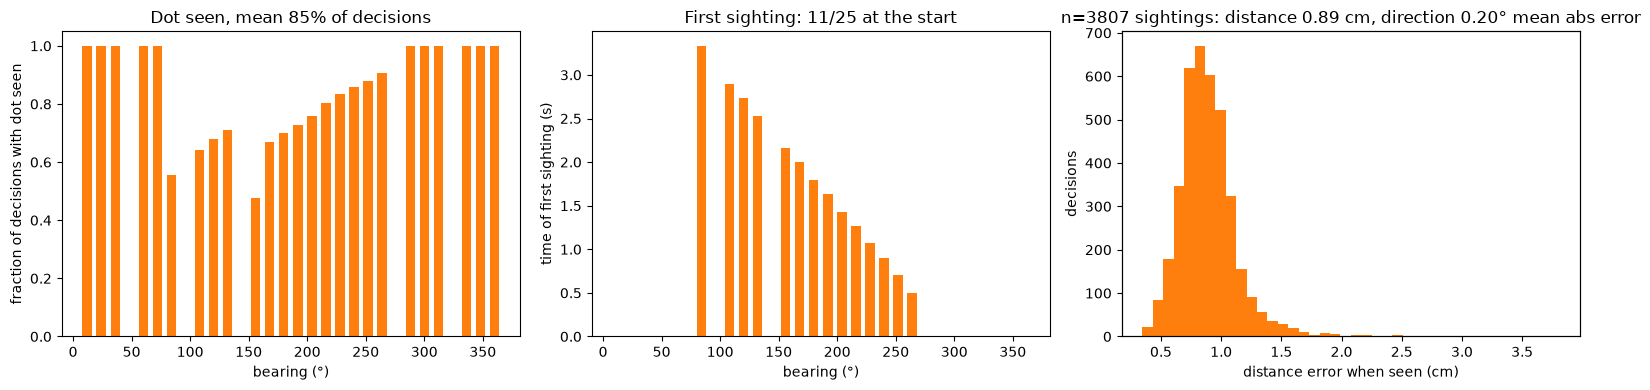

In [41]:
log = {b: runs[MAIN, b]['log'] for b in bearings}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
vis = [np.mean([l['visible'] for l in log[b]]) for b in bearings]
first = [next((l['t'] for l in log[b] if l['visible']), np.nan) for b in bearings]
ax[0].bar(bearings, vis, width=8, color='tab:orange'); ax[0].set(xlabel='bearing (°)', ylabel='fraction of decisions with dot seen', ylim=(0, 1.05),
                                                      title=f'Dot seen, mean {np.mean(vis):.0%} of decisions')
ax[1].bar(bearings, first, width=8, color='tab:orange')
ax[1].set(xlabel='bearing (°)', ylabel='time of first sighting (s)', title=f'First sighting: {sum(f == 0 for f in first)}/25 at the start')
dist_err = [100 * (l['est_dist'] - l['true_dist']) for b in bearings for l in log[b] if l['visible']]
dir_err = [(l['est_dir_deg'] - l['true_dir_deg'] + 180) % 360 - 180 for b in bearings for l in log[b] if l['visible']]
ax[2].hist(dist_err, bins=40, color='tab:orange'); ax2 = ax[2].twiny()
ax[2].set(xlabel='distance error when seen (cm)', ylabel='decisions',
          title=f'n={len(dist_err)} sightings: distance {np.mean(np.abs(dist_err)):.2f} cm, direction {np.mean(np.abs(dir_err)):.2f}° mean abs error')
ax2.set_xticks([]); plt.tight_layout(); plt.show()

### 6. Time to park: what the network predicts while driving vs the expert's real time left

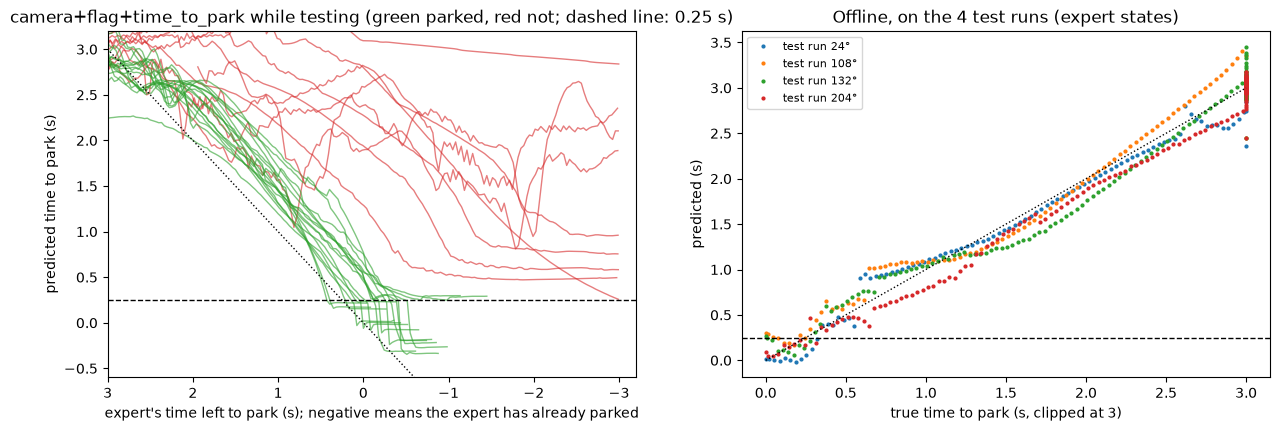

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for b in bearings:
    L = log[b]; t = np.array([l['t'] for l in L]); pred = np.array([l['ttp_s'] for l in L])
    ax[0].plot(ref[str(b)]['park_time_s'] - t, pred, color='tab:green' if runs[MAIN, b]['parked'] else 'tab:red', alpha=0.6, lw=1)
ax[0].plot([-3, 3], [-3, 3], 'k:', lw=1); ax[0].axhline(THRESH, color='k', lw=1, ls='--')
ax[0].set(xlim=(3, -3.2), ylim=(-0.6, 3.2), xlabel="expert's time left to park (s); negative means the expert has already parked",
          ylabel='predicted time to park (s)', title=f'{MAIN} while testing (green parked, red not; dashed line: 0.25 s)')
with torch.no_grad():
    for e in test:
        pred = camera_models[MAIN](torch.from_numpy(camera_inputs(e, CAMERA_MODELS[MAIN][0])))[1].numpy() * CLIP
        ax[1].plot(time_to_park(e) * CLIP, pred, '.', ms=4, label=f"test run {e['bearing']}°")
ax[1].plot([0, 3], [0, 3], 'k:', lw=1); ax[1].axhline(THRESH, color='k', lw=1, ls='--')
ax[1].set(xlabel='true time to park (s, clipped at 3)', ylabel='predicted (s)', title='Offline, on the 4 test runs (expert states)')
ax[1].legend(fontsize=8); plt.show()

## Iteration 8: scaled wheel angles

### Why: the inputs are on very different scales

The network takes its inputs as they come. The wheel angles keep adding up over a run, while the dot inputs stay between -1 and 1 and the wheel speeds between -3 and 3. The tables below show this on the training data and on two test runs.

In [43]:
import v2_results
INPUT_NAMES = ['angle FR', 'angle FL', 'angle BL', 'angle BR', 'speed FR', 'speed FL', 'speed BL', 'speed BR',
               'mean angle', 'R-L angle', 'mean speed', 'R-L speed', 'dot distance', 'dot sin', 'dot cos', 'visible']
Xtrain = np.concatenate([camera_inputs(e, [0, 1, 2, 3]) for e in train])
pd.DataFrame({'min': Xtrain.min(0), 'max': Xtrain.max(0), 'standard deviation': Xtrain.std(0)}, index=INPUT_NAMES).round(2)

,min,max,standard deviation
angle FR,-8.110000,13.36,4.90
angle FL,-7.640000,13.30,5.04
angle BL,-7.730000,13.37,5.08
angle BR,-8.190000,13.41,4.94
speed FR,-3.170000,3.18,2.02
speed FL,-3.140000,3.22,1.88
speed BL,-3.190000,3.21,1.90
speed BR,-3.190000,3.21,2.04
mean angle,-0.000000,4.76,1.73
R-L angle,-17.389999,17.27,9.35


### First and last row of two test runs, with what the expert and `camera+flag+time_to_park` output

In [44]:
w6 = np.load('models/camera_flag_ttp.npz')
def net(w, x):
    h = x
    for layer in ('shared.0', 'shared.2'):
        h = np.maximum(h @ w[layer + '.weight'].T + w[layer + '.bias'], 0)
    return h @ w['wheels.weight'].T + w['wheels.bias'], float((h @ w['park.weight'].T + w['park.bias'])[0]) * float(w['ttp_clip'])

tables = {}
for b in (24, 204):
    e = next(e for e in test if e['bearing'] == b)
    t = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == b)['archive'])['time_s']
    X = camera_inputs(e, [0, 1, 2, 3])
    cols = {}
    for i, label in ((0, 'start'), (len(X) - 1, 'end (expert parks)')):
        wheels, ttp = net(w6, X[i])
        cols[f'{label}, t = {t[i]:.2f} s'] = list(np.round(X[i], 2)) + [
            ', '.join(f'{v:.2f}' for v in e['wheels'][i]), f'{t[-1] - t[i]:.2f}',
            ', '.join(f'{v:.2f}' for v in wheels), f"{ttp:.2f} ({'PARK' if ttp <= THRESH else 'drive'})"]
    tables[f'{b}° test run'] = pd.DataFrame(cols, index=INPUT_NAMES + ['expert wheels FR, FL, BL, BR', 'expert time left (s)',
                                                                  'model wheels FR, FL, BL, BR', 'model time to park (s)'])
pd.concat(tables, axis=1)

24° test run  \
                                     start, t = 0.00 s   
angle FR                                           0.0   
angle FL                                           0.0   
angle BL                                           0.0   
angle BR                                           0.0   
speed FR                                           0.0   
speed FL                                           0.0   
speed BL                                           0.0   
speed BR                                           0.0   
mean angle                                         0.0   
R-L angle                                          0.0   
mean speed                                         0.0   
R-L speed                                          0.0   
dot distance                                      1.11   
dot sin                                           0.41   
dot cos                                           0.91   
visible                                            1.0   
expert wheels FR, FL, BL, BR  3.00, -3.00, -3.00, 3.00   
expert time left (s)                              3.35   
model wheels FR, FL, BL, BR   0.74, -0.44, -0.50, 0.81   
model time to park (s)                    2.36 (drive)   

                                                             \
                             end (expert parks), t = 3.35 s   
angle FR                                               4.77   
angle FL                                               2.29   
angle BL                                               2.29   
angle BR                                               4.73   
speed FR                                              -0.39   
speed FL                                                0.4   
speed BL                                               0.41   
speed BR                                              -0.39   
mean angle                                             3.52   
R-L angle                                              2.46   
mean speed                                             0.01   
R-L speed                                              -0.8   
dot distance                                           0.73   
dot sin                                               -0.03   
dot cos                                                 1.0   
visible                                                 1.0   
expert wheels FR, FL, BL, BR         0.00, 0.00, 0.00, 0.00   
expert time left (s)                                   0.00   
model wheels FR, FL, BL, BR        -0.46, 0.38, 0.35, -0.43   
model time to park (s)                          0.02 (PARK)   

                                         204° test run  \
                                     start, t = 0.00 s   
angle FR                                           0.0   
angle FL                                           0.0   
angle BL                                           0.0   
angle BR                                           0.0   
speed FR                                           0.0   
speed FL                                           0.0   
speed BL                                           0.0   
speed BR                                           0.0   
mean angle                                         0.0   
R-L angle                                          0.0   
mean speed                                         0.0   
R-L speed                                          0.0   
dot distance                                       0.0   
dot sin                                            0.0   
dot cos                                            0.0   
visible                                            0.0   
expert wheels FR, FL, BL, BR  -3.00, 3.00, 3.00, -3.00   
expert time left (s)                              6.11   
model wheels FR, FL, BL, BR   -0.52, 0.63, 0.52, -0.44   
model time to park (s)                    2.44 (drive)   

                                                             
                             end (exper

Reading the tables:

- The wheel angles reach about 14 at 204°, and their standard deviation over the training data is about 5. The dot inputs never leave -1 to 1 (distance up to about 1.2 m).
- At the start the model turns the right way but gives about 0.6 rad/s where the expert gives 3.
- At the end the model parks on the expert's states (time to park 0.02 s and 0.09 s).

### What changed

The six angle inputs (4 wheel angles, mean angle, right minus left angle) are standardised: the training-set mean is subtracted and the result divided by the training-set standard deviation. Nothing else changes: same inputs, outputs, loss, seed 7 and 300 epochs. The scaling is folded into the first layer when the model is saved, so the saved network takes raw inputs and runs in the same test loop. `train_v2.py` trains it; without `--scale-angles` it reproduces `camera+flag+time_to_park` exactly.

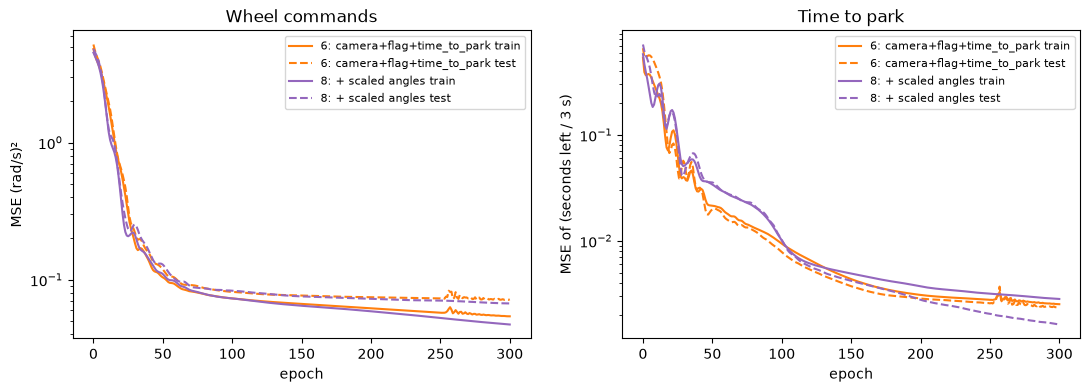

In [45]:
h6 = camera_history[camera_history.model == 'camera+flag+time_to_park']
h8 = v2_results.history('camera_flag_ttp_scaled')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, h, park_col, c in (('6: camera+flag+time_to_park', h6, 'park_loss', 'tab:orange'), ('8: + scaled angles', h8, 'time_to_park_mse', 'tab:purple')):
    ax[0].plot(h.epoch, h.train_wheel_mse, color=c, label=f'{label} train'); ax[0].plot(h.epoch, h.test_wheel_mse, '--', color=c, label=f'{label} test')
    ax[1].plot(h.epoch, h['train_' + park_col], color=c, label=f'{label} train'); ax[1].plot(h.epoch, h['test_' + park_col], '--', color=c, label=f'{label} test')
ax[0].set(title='Wheel commands', ylabel='MSE (rad/s)²'); ax[1].set(title='Time to park', ylabel='MSE of (seconds left / 3 s)')
for a in ax: a.set(xlabel='epoch', yscale='log'); a.legend(fontsize=8)
plt.show()

### Testing: 25 bearings, compared with iteration 6

In [46]:
iter8 = pd.concat([v2_results.tests('camera_flag_ttp', '6: camera+flag+time_to_park'), v2_results.tests('camera_flag_ttp_scaled', '8: + scaled angles')])
v2_results.summary(iter8)

,parked (of 25),dot in view at start (of 11),dot out of view at start (of 14),test runs (of 4),median final error (cm),median heading error (°)
model,,,,,,
6: camera+flag+time_to_park,16,7,9,2,14.5,17.8
8: + scaled angles,14,11,3,1,19.9,26.7


In [47]:
iter8.pivot(index=['split', 'bearing', 'seen_at_start'], columns='model', values='parked')

model                        6: camera+flag+time_to_park  8: + scaled angles
split bearing seen_at_start                                                 
test  24      True                                  True                True
      108     False                                False               False
      132     False                                False               False
      204     False                                 True               False
train 12      True                                  True                True
      36      True                                 False                True
      60      True                                 False                True
      72      True                                 False                True
      84      False                                False               False
      120     False                                False               False
      156     False                                False               False
      168     False                                 True               False
      180     False                                 True               False
      192     False                                 True               False
      216     False                                 True               False
      228     False                                 True                True
      240     False                                 True                True
      252     False                                 True               False
      264     False                                 True                True
      288     True                                  True                True
      300     True                                  True                True
      312     True                                  True                True
      336     True                                  True                True
      348     True                                  True                True
      360     True                                 False                True

Scaling fixed every bearing where the dot starts in view (11 of 11, up from 7) but made the search for a dot behind the robot worse (3 of 14, down from 9). The total fell from 16 to 14 of 25. One seed is not enough to tell how much of this is the change and how much is chance, which is what iteration 9 measures.

## Iterations 9 to 11: the same model with three new seeds

### What the seed changes

Iteration 8 trained once, with seed 7. The seed only sets the starting weights. Iterations 9, 10 and 11 train the same model on the same data with seeds 1, 2 and 3, and test each on the same 25 bearings. This shows how much of any result is chance.

In [48]:
SEEDS = {'seed 7 (iteration 8)': 'camera_flag_ttp_scaled', 'seed 1 (iteration 9)': 'camera_flag_ttp_scaled_seed1',
         'seed 2 (iteration 10)': 'camera_flag_ttp_scaled_seed2', 'seed 3 (iteration 11)': 'camera_flag_ttp_scaled_seed3'}
seed_tests = pd.concat([v2_results.tests(f, s) for s, f in SEEDS.items()])
seed_table = v2_results.summary(seed_tests)
seed_table

,parked (of 25),dot in view at start (of 11),dot out of view at start (of 14),test runs (of 4),median final error (cm),median heading error (°)
model,,,,,,
seed 7 (iteration 8),14,11,3,1,19.9,26.7
seed 1 (iteration 9),0,0,0,0,12.5,21.7
seed 2 (iteration 10),4,4,0,0,44.3,15.5
seed 3 (iteration 11),21,8,13,4,20.6,3.6


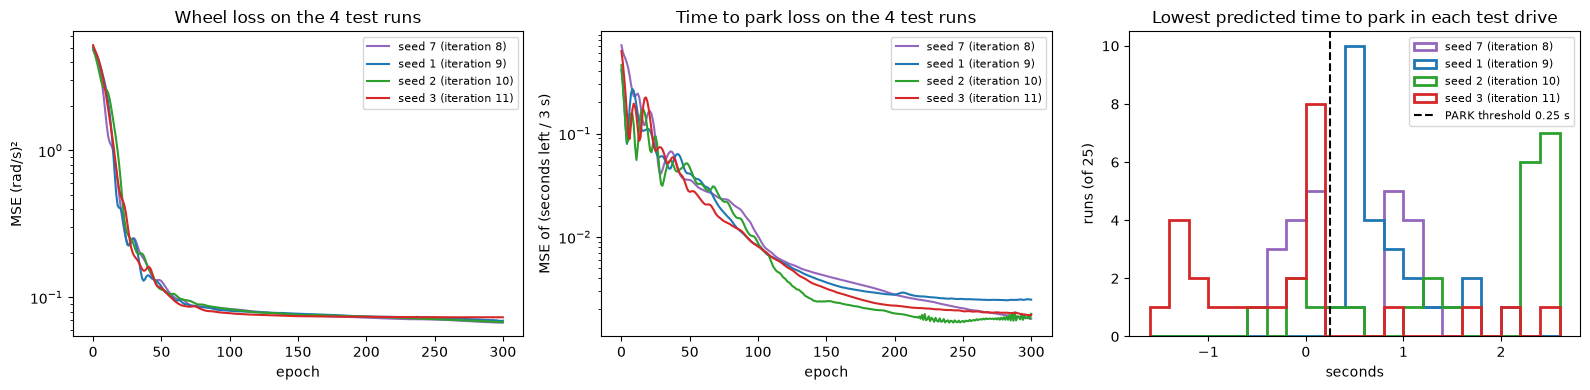

In [49]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for (label, f), c in zip(SEEDS.items(), ['tab:purple', 'tab:blue', 'tab:green', 'tab:red']):
    h = v2_results.history(f)
    ax[0].plot(h.epoch, h.test_wheel_mse, color=c, label=label); ax[1].plot(h.epoch, h.test_time_to_park_mse, color=c, label=label)
    mins = [min(l['ttp_s'] for l in json.loads(Path(f'camera_loop/{f}/run_{b}.json').read_text())['log']) for b in ref]
    ax[2].hist(mins, bins=np.arange(-1.6, 2.8, 0.2), histtype='step', lw=2, color=c, label=label)
ax[0].set(title='Wheel loss on the 4 test runs', xlabel='epoch', yscale='log', ylabel='MSE (rad/s)²')
ax[1].set(title='Time to park loss on the 4 test runs', xlabel='epoch', yscale='log', ylabel='MSE of (seconds left / 3 s)')
ax[2].axvline(THRESH, color='k', ls='--', label='PARK threshold 0.25 s')
ax[2].set(title='Lowest predicted time to park in each test drive', xlabel='seconds', ylabel='runs (of 25)')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [50]:
pd.DataFrame({'ended within 20 cm of the expert (of 25)': seed_tests.groupby('model', sort=False).final_error_cm.apply(lambda e: int((e < 20).sum())),
              'parked (of 25)': seed_table['parked (of 25)']})

,ended within 20 cm of the expert (of 25),parked (of 25)
model,,
seed 7 (iteration 8),13,14
seed 1 (iteration 9),19,0
seed 2 (iteration 10),8,4
seed 3 (iteration 11),12,21


### What the seeds show

- Parked counts run from 0 to 21 of 25 with nothing changed but the seed. A difference of a few runs between two single-seed results means nothing.
- The losses on the test runs are almost the same for all four seeds. Training looks equally good offline.
- The driving is better than the parked count suggests. Seed 1 ends within 20 cm of the expert in 19 of 25 runs and parks in none: its predicted time to park never drops below 0.35 s, so PARK never fires.
- So the fixed 0.25 s threshold decides most of the outcome. The model has never seen what being parked looks like, because every expert run stops at the PARK row. Iteration 12 adds that.

## Iteration 12: 100 rows after the expert parks

Every expert run stops at its PARK row, so the network never sees what being parked looks like. Iteration 12 adds 100 rows (3.3 s) after PARK to every training run. In those rows the wheel command is 0 and the time to park is 0.

The rows come from replaying the expert in the fast simulator past its PARK command (`policy_replay` with `"expert_tail_steps": 3400`), with the wheels stopped and the arm held. Before PARK the replay matches the saved expert data to 3e-8. The camera inputs for the new rows come from the same camera, detector and tracker (`expert_tail.py`). Everything else is iteration 8. Because the seeds vary so much, it is trained and tested with all four seeds (7, 1, 2, 3).

In [51]:
tail = np.load('park_tail/tail_24.npz')
print(f"rows per run: {len(tail['x'])}, from {tail['time_since_park_s'][0]:.2f} s to {tail['time_since_park_s'][-1]:.2f} s after PARK")
pd.DataFrame({'largest wheel speed (rad/s)': [float(np.abs(np.load(f)['x'][:, 4:8]).max()) for f in sorted(Path('park_tail').glob('tail_*.npz'))],
              'dot visible (fraction of rows)': [float(np.load(f)['camera'][:, 3].mean()) for f in sorted(Path('park_tail').glob('tail_*.npz'))]},
             index=[f.stem for f in sorted(Path('park_tail').glob('tail_*.npz'))]).describe().loc[['mean', 'min', 'max']].round(2)

rows per run: 100, from 0.01 s to 3.31 s after PARK


,largest wheel speed (rad/s),dot visible (fraction of rows)
mean,0.20,0.56
min,0.06,0.00
max,0.39,1.00


### Iteration 12: results over four seeds

In [52]:
pairs = {s: (f'camera_flag_ttp_scaled{"" if s == 7 else f"_seed{s}"}', f'camera_flag_ttp_scaled_tail100{"" if s == 7 else f"_seed{s}"}') for s in (7, 1, 2, 3)}
rows = []
for s, (before, after) in pairs.items():
    for label, f in (('8 to 11: scaled', before), ('12: + parked rows', after)):
        d = v2_results.tests(f)
        mins = [min(l['ttp_s'] for l in json.loads(Path(f'camera_loop/{f}/run_{b}.json').read_text())['log']) for b in ref]
        rows.append({'seed': s, 'model': label, 'parked (of 25)': int(d.parked.sum()),
                     'dot in view at start (of 11)': int(d[d.seen_at_start].parked.sum()), 'dot out of view at start (of 14)': int(d[~d.seen_at_start].parked.sum()),
                     'ended within 20 cm (of 25)': int((d.final_error_cm < 20).sum()), 'median final error (cm)': round(d.final_error_cm.median(), 1),
                     'median lowest time to park (s)': round(float(np.median(mins)), 2)})
iter12 = pd.DataFrame(rows).set_index(['seed', 'model'])
iter12

parked (of 25)  dot in view at start (of 11)  \
seed model                                                             
7    8 to 11: scaled                14                            11   
     12: + parked rows               9                             2   
1    8 to 11: scaled                 0                             0   
     12: + parked rows              12                             2   
2    8 to 11: scaled                 4                             4   
     12: + parked rows               2                             1   
3    8 to 11: scaled                21                             8   
     12: + parked rows               0                             0   

                        dot out of view at start (of 14)  \
seed model                                                 
7    8 to 11: scaled                                   3   
     12: + parked rows                                 7   
1    8 to 11: scaled                                   0   
     12: + parked rows                                10   
2    8 to 11: scaled                                   0   
     12: + parked rows                                 1   
3    8 to 11: scaled                                  13   
     12: + parked rows                                 0   

                        ended within 20 cm (of 25)  median final error (cm)  \
seed model                                                                    
7    8 to 11: scaled                            13                     19.9   
     12: + parked rows                          22                     11.2   
1    8 to 11: scaled                            19                     12.5   
     12: + parked rows                          19                     13.0   
2    8 to 11: scaled                             8                     44.3   
     12: + parked rows                           9                     28.9   
3    8 to 11: scaled                            12                     20.6   
     12: + parked rows                           3                     39.1   

                        median lowest time to park (s)  
seed model                                              
7    8 to 11: scaled                              0.15  
     12: + parked rows                            0.47  
1    8 to 11: scaled                              0.68  
     12: + parked rows                            0.28  
2    8 to 11: scaled                              2.31  
     12: + parked rows                            1.43  
3    8 to 11: scaled                             -0.10  
     12: + parked rows                            2.40

In [53]:
iter12.groupby('model').agg(['mean', 'min', 'max'])[['parked (of 25)', 'ended within 20 cm (of 25)']].round(2)

parked (of 25)         ended within 20 cm (of 25)        
                            mean min max                       mean min max
model                                                                      
12: + parked rows           5.75   0  12                      13.25   3  22
8 to 11: scaled             9.75   0  21                      13.00   8  19

Reading the results:

- Averaged over the four seeds, iteration 12 parked 5.75 of 25 against 9.75 before. The seeds still range from 0 to 12.
- Runs ending within 20 cm of the expert hardly changed (13.25 against 13 on average).
- The training losses are not comparable with iteration 8, because a third of the rows are now easy parked rows.
- The parked rows did not make PARK reliable. The bigger problem is that each seed learns a different time-to-park scale, and one fixed threshold cannot suit them all.

## Iteration 13: wheel encoders instead of simulator wheel values

### Iteration 13: what changed

Until now the 12 wheel inputs came straight from the simulator's joint angles and joint speeds. Iteration 13 reads them from simulated wheel encoders (`sensors.py`):

- Each wheel has an incremental encoder with 4096 counts per revolution (an assumed, common 12-bit resolution). The angle moves in steps of 2π/4096 rad.
- Speed is not measured directly. It is the change in counted angle since the previous reading, divided by 1/30 s, so it lags the true speed.
- The 12 inputs are built from these readings exactly as before, and the tracker uses the encoder speeds when the dot is hidden.

The network now sees only sensor readings: wheel encoders and the camera. The outputs are unchanged (four wheel speed commands and time to park). Everything else is iteration 12, trained and tested with the same four seeds.

`sensors.py` collects the sensors in one `Sensors` class. An IMU can be added there with a `reset()` and a `read(frame)`, and its readings added to the inputs.

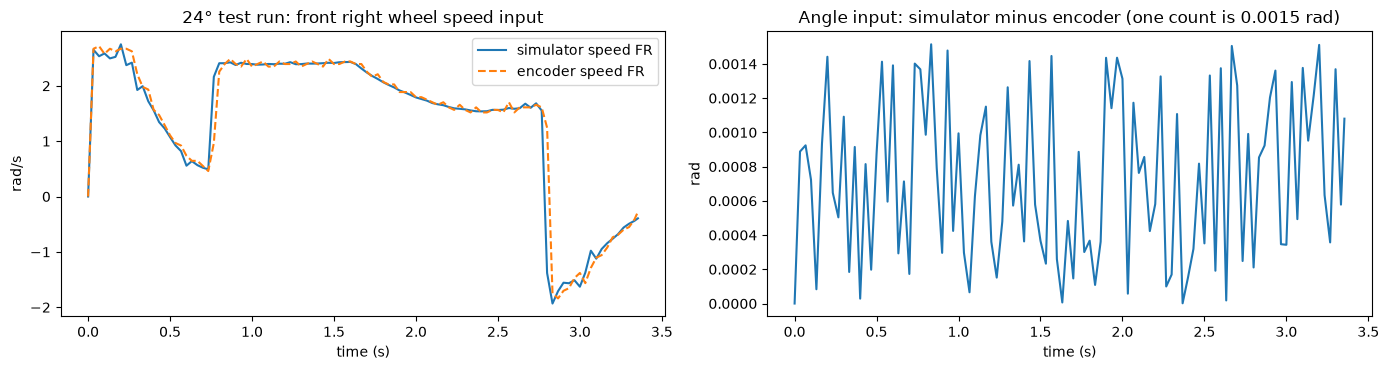

In [54]:
import sensors
e24 = next(e for e in test if e['bearing'] == 24)
a24 = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == 24)['archive'])
enc = sensors.WheelEncoders.features_for_run(a24['joint_positions'][:, :4])
t24 = a24['time_s']
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(t24, e24['x'][:, 4], label='simulator speed FR'); ax[0].plot(t24, enc[:, 4], '--', label='encoder speed FR')
ax[0].set(xlabel='time (s)', ylabel='rad/s', title='24° test run: front right wheel speed input'); ax[0].legend()
ax[1].plot(t24, e24['x'][:, 0] - enc[:, 0])
ax[1].set(xlabel='time (s)', ylabel='rad', title='Angle input: simulator minus encoder (one count is 0.0015 rad)')
plt.tight_layout(); plt.show()

### Iteration 13: results over four seeds

In [55]:
rows = []
for s in (7, 1, 2, 3):
    suffix = '' if s == 7 else f'_seed{s}'
    for label, f in (('12: simulator wheel values', 'camera_flag_ttp_scaled_tail100' + suffix), ('13: wheel encoders', 'camera_flag_ttp_scaled_tail100_encoders' + suffix)):
        d = v2_results.tests(f)
        rows.append({'seed': s, 'model': label, 'parked (of 25)': int(d.parked.sum()),
                     'dot in view at start (of 11)': int(d[d.seen_at_start].parked.sum()), 'dot out of view at start (of 14)': int(d[~d.seen_at_start].parked.sum()),
                     'test runs (of 4)': int(d[d.split == 'test'].parked.sum()),
                     'ended within 20 cm (of 25)': int((d.final_error_cm < 20).sum()), 'median final error (cm)': round(d.final_error_cm.median(), 1)})
iter13 = pd.DataFrame(rows).set_index(['seed', 'model'])
iter13

parked (of 25)  dot in view at start (of 11)  \
seed model                                                                      
7    12: simulator wheel values               9                             2   
     13: wheel encoders                      24                            10   
1    12: simulator wheel values              12                             2   
     13: wheel encoders                      22                            10   
2    12: simulator wheel values               2                             1   
     13: wheel encoders                      11                             8   
3    12: simulator wheel values               0                             0   
     13: wheel encoders                      15                            11   

                                 dot out of view at start (of 14)  \
seed model                                                          
7    12: simulator wheel values                                 7   
     13: wheel encoders                                        14   
1    12: simulator wheel values                                10   
     13: wheel encoders                                        12   
2    12: simulator wheel values                                 1   
     13: wheel encoders                                         3   
3    12: simulator wheel values                                 0   
     13: wheel encoders                                         4   

                                 test runs (of 4)  ended within 20 cm (of 25)  \
seed model                                                                      
7    12: simulator wheel values                 1                          22   
     13: wheel encoders                         4                          24   
1    12: simulator wheel values                 2                          19   
     13: wheel encoders                         3                          14   
2    12: simulator wheel values                 0                           9   
     13: wheel encoders                         1                          14   
3    12: simulator wheel values                 0                           3   
     13: wheel encoders                         1                          14   

                                 median final error (cm)  
seed model                                                
7    12: simulator wheel values                     11.2  
     13: wheel encoders                              7.4  
1    12: simulator wheel values                     13.0  
     13: wheel encoders                             18.5  
2    12: simulator wheel values                     28.9  
     13: wheel encoders                             17.1  
3    12: simulator wheel values                     39.1  
     13: wheel encoders                             17.3

In [56]:
iter13.groupby('model').agg(['mean', 'min', 'max'])[['parked (of 25)', 'ended within 20 cm (of 25)', 'median final error (cm)']].round(1)

parked (of 25)         ended within 20 cm (of 25)  \
                                     mean min max                       mean   
model                                                                          
12: simulator wheel values            5.8   0  12                       13.2   
13: wheel encoders                   18.0  11  24                       16.5   

                                   median final error (cm)              
                           min max                    mean   min   max  
model                                                                   
12: simulator wheel values   3  22                    23.0  11.2  39.1  
13: wheel encoders          14  24                    15.1   7.4  18.5

In [57]:
best = v2_results.tests('camera_flag_ttp_scaled_tail100_encoders', '13: wheel encoders, seed 7')
best[['split', 'bearing', 'seen_at_start', 'parked', 'final_error_cm', 'heading_error_deg', 'park_time_vs_expert_s']].sort_values('final_error_cm', ascending=False).round(2)

,split,bearing,seen_at_start,parked,final_error_cm,heading_error_deg,park_time_vs_expert_s
0,train,12,True,False,25.38,23.98,NaN
3,train,60,True,True,15.49,11.44,-0.44
10,train,168,False,True,10.16,7.20,-0.60
9,train,156,False,True,9.50,7.06,-0.36
12,train,192,False,True,9.20,5.01,-0.90
22,train,336,True,True,9.00,9.17,0.25
14,train,216,False,True,8.93,7.58,-0.98
23,train,348,True,True,8.73,17.57,-0.96
13,test,204,False,True,8.68,8.25,-0.98
8,test,132,False,True,8.31,5.77,0.26


Reading the results:

- With encoders the model parked a mean of 18 of 25 over the four seeds (11 to 24), against 5.75 (0 to 12) with simulator wheel values. Every seed improved.
- Seed 7 parks 24 of 25 with a median final error of 7.4 cm, and all 4 test runs park within 9 cm of the expert. The model given the true dot position (iteration 3) parked 23 of 25.
- We do not know yet why encoders help this much. The encoder speed inputs are not smoother row to row than the simulator's (0.156 against 0.166 rad/s mean change). The tracker also switched to encoder speeds, so two things changed together. Testing each separately would show which one matters.
- The seeds still differ (11 to 24 parked), so results should be reported over several seeds.

### Iteration 13: 3D replay of seed 7

Solid robot: the iteration 13 model (seed 7), driving from the camera and wheel encoders. Cyan ghost: the expert. All 25 bearings are in the dropdown, labelled TRAIN or TEST. The panel on the right shows the predicted time to park, the wheel commands and the park and final differences from the expert.

These runs were repeated with the full robot state logged (`FULL_FRAMES=1`, results in `camera_loop_frames/`). The table under the player checks that they end where the runs above ended.

<a href="/files/driving_v2/closed_loop_native/viewer_iter13_seed7.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [58]:
path = replay_v2.build_camera_viewer('camera_flag_ttp_scaled_tail100_encoders', 'iter13_seed7')
lazy_player('/files/driving_v2/closed_loop_native/' + path.name)

In [59]:
check = []
for b in v2_results.REF:
    a = json.loads(Path(f'camera_loop/camera_flag_ttp_scaled_tail100_encoders/run_{b}.json').read_text())
    c = json.loads(Path(f'camera_loop_frames/camera_flag_ttp_scaled_tail100_encoders/run_{b}.json').read_text())
    check.append(dict(bearing=int(b), parked_before=a['parked'], parked_now=c['parked'],
                      final_position_difference_mm=1000 * float(np.hypot(*np.subtract(a['final_base'], c['final_base'])))))
pd.DataFrame(check).sort_values('bearing').set_index('bearing').T.round(3)

bearing,12,24,36,60,72,84,108,120,132,156,...,228,240,252,264,288,300,312,336,348,360
parked_before,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
parked_now,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
final_position_difference_mm,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Arm: plan and expected results

### What the arm network will do

The expert works in two phases. While it drives, it holds the arm still. Once it has parked, it reaches for the dot with the arm and stops when the gripper is within 1 cm of it. The arm network copies the second phase. It takes over at PARK, from the iteration 13 driving model.

| | Count | Details |
|---|---|---|
| Input: arm joint angles | 7 | arm encoders (`sensors.ArmEncoders`): absolute angle in whole ticks, 3,686,400 per turn on joints 1 to 4 and 2,534,400 on joints 5 to 7 (Kinova datasheet for the Jaco 2 actuators) |
| Input: arm joint speeds | 7 | change in encoder angle over 1/30 s |
| Input: dot x, y and height | 3 | camera and tracker, which now keeps the height |
| Input: dot visible flag | 1 | camera |
| Input: time since PARK | 1 | clock |
| Output: arm joint torques | 7 | clipped at ±30 Nm, like the expert's |
| Output: time to stop | 1 | stop when it is 0.25 s or less, latched |

- The network is a 2×64 ReLU MLP. Inputs and each torque are standardised, and the scaling is folded into the weights, as in iteration 8.
- It runs at 30 Hz, like the driving network. Each torque command is held for 33 ms while the physics runs at 1 kHz.
- The fingers do not move, so they are not inputs.
- Until PARK the arm is held by the same hold controller as the expert. After PARK there is no hold controller: the network's torques move the arm and also keep it up after stop. A run ends 0.5 s after stop, or 1 s after the expert's stop time.
- Training rows run from the expert's PARK to 0.5 s after the expert's stop, with time to stop 0 after the stop. There are 21 training runs, one per training bearing.
- The loss is the one used for driving: mean squared error on the outputs with equal weight per run, plus the weighted time-to-stop term. Results are also reported as the number of bearings where the gripper ends within 1 cm of the dot.
- Every version is trained with four seeds (7, 1, 2 and 3).

### Smoke tests before training

| Test | What it checks | Expected result |
|---|---|---|
| 1. Iteration 13, seed 7, through the changed simulator | the change does not affect driving | the same final positions, to the millimetre |
| 2. The expert's own 1 kHz arm torques sent through the new arm input | the arm input is wired correctly | the same reach as the expert, gripper within 1 cm |
| 3. The expert's torques averaged over each 33 ms and held | 30 Hz is fast enough for the arm | gripper within 1 cm on most bearings; if not, the arm network moves to 100 Hz |
| 5. Dot in the camera view after PARK | where the dot inputs come from during the reach | probably out of view, so the tracker's estimate is used; this is fine because the robot does not move |
| 6. Train on one bearing and test it in the simulator | the inputs carry enough information for one reach | the gripper ends within 1 cm on that bearing |

Test 4, the expert's torques against the real actuator limits, is not run: we take the expert's torques as correct.

### Expected results and what we do if they fail

- The reach should be easier than driving to learn. The dot does not move once the robot has parked, and the arm starts from almost the same pose every time.
- The risk is drift: a small torque error at the shoulder moves the gripper a long way. If the reach drifts, the next steps are the joint torque sensors as 7 more inputs (±0.4 Nm), then extra training runs around the expert's path (DART).
- If the network does not stop, we add more rows after the expert's stop, as iteration 12 did for PARK.
- Later, the arm network will run for the whole run with a parked flag as an input, so the hold controller before PARK is replaced as well.

### Arm: what the expert does

The expert's full runs were recorded for all 30 bearings with the fast simulator's expert collector, every 1 ms, from the start to the expert's stop (`v2_sensors/arm/data/expert_full`, 18 s to collect). Their PARK times match the driving data to the millisecond.

- The expert stops when the gripper is within 1 cm of the dot and more than 8 s have passed since the start (`controller.cpp:91`). So 23 of the 30 runs stop at exactly 8.0 s, however early the gripper got there. The arm network therefore gets the time since the start as an input, as well as the time since PARK.
- On 204° and 228° the expert does not get within 1 cm. It stalls about 11.5 mm from the dot and stops 3 s later. 204° is a test bearing.
- The brief (slide 4) names the outputs `torque_arm` and `wheel_cmds`. The arm network therefore outputs the 7 torques directly. A network that outputs target angles for a fixed PD loop would change the command type.
- The wheels are different. A wheel command is a speed, and the simulator turns it into torque every 1 ms with 30 × (commanded speed − actual speed) (`physics.cpp:106`). This is the simulator's motor model, and it keeps correcting while a 30 Hz command is held. The arm torques go to the joints as they are, with nothing in between.

### Arm: smoke tests

The stepping server (`sensor_parking`) has new options, and without them it behaves as before:

- `arm`: after PARK the client's 7 torques drive the arm and `stop` ends the run 0.5 s later. Until the first arm command after PARK the hold controller keeps the arm.
- `expert_drive`: the expert drives and parks itself, so the arm can be tested on its own.
- `expert_arm_hz`: the expert's own arm controller runs after PARK, but its torque is only taken at this rate and held in between.

| Test | Result |
|---|---|
| 1. Iteration 13, seed 7, through the changed server | the same 24 of 25 parked, final positions identical to the millimetre |
| 2. The expert's own 1 kHz torques sent through the arm input | the expert's reach reproduced exactly on all 30 bearings |
| 3. The expert's torques averaged over each 33 ms and held, without feedback | the gripper ends 0.2 to 1.2 m from the dot |
| 3b. The expert's own controller, its torque taken at a lower rate and held | works only at 1 kHz (table below) |
| 5. Dot in view after PARK | in view on 9 of the 24 parked runs; otherwise the tracker's estimate is within about 1 to 4 cm |

Test 4, the expert's torques against the real actuator limits, is not run, because we take the expert's torques as correct.

In [60]:
ARM = Path('../arm')
t2 = pd.DataFrame(json.loads((ARM / 'smoke/test2_1khz.json').read_text()))
rows = []
for hz in (1000, 500, 250, 100, 30):
    d = pd.DataFrame(json.loads((ARM / f'smoke/test3b_expert_{hz}hz.json').read_text()))
    rows.append({'rate (Hz)': hz, 'matches the expert (of 30)': int((d.at_stop_mm <= np.maximum(10, t2.expert_stop_mm + 1)).sum()),
                 'median distance at the expert stop (mm)': round(d.at_stop_mm.median(), 1),
                 'largest distance (mm)': round(d.at_stop_mm.max(), 1)})
print('Test 2: largest difference from the expert at its stop (mm):', float((t2.at_stop_mm - t2.expert_stop_mm).abs().max()))
pd.DataFrame(rows).set_index('rate (Hz)')

Test 2: largest difference from the expert at its stop (mm): 1.7763568394002505e-15


,matches the expert (of 30),median distance at the expert stop (mm),largest distance (mm)
rate (Hz),,,
1000,30,4.2,11.7
500,0,65.1,95.9
250,0,452.1,629.6
100,0,595.8,814.4
30,0,637.8,55856.2


Test 3b is the main finding. The expert's arm controller has stiff gains (100 on the angle error, 30 on the speed) on light joints. Its torque is right for one millisecond. Held for 2 ms the arm overshoots, and held for 33 ms it swings away from the dot.

### Arm: 30 Hz torque networks (iterations 14 to 16)

#### Iterations 14 to 16: plan and expected results

This entry was added after the runs. The expectation below is the one stated before training.

Three networks output the 7 arm torques once per 30 Hz decision (`v2_sensors/arm/train_arm.py`), to see what happens when torques are held for 33 ms:

| Iteration | Model | Trained on | Torque target |
|---|---|---|---|
| 14 | `arm30_sample_b12` | bearing 12 only | the expert's torque at the decision step |
| 15 | `arm30_sample` | the 21 training bearings | the expert's torque at the decision step |
| 16 | `arm30_mean` | the 21 training bearings | the expert's torque averaged over the 33 ms until the next decision |

- 19 inputs: arm encoder angles (7) and speeds (7), the dot in the robot frame (3, from the simulator for this test, not the camera), time since PARK and time since the start.
- Outputs: the 7 torques and the time to stop. 2×64 ReLU, 5,960 parameters, inputs and torques standardised, Adam with learning rate 0.01, 300 full-batch epochs, seed 7.
- Rows: every 30 Hz decision from the expert's PARK to its stop, about 110 per run.
- Loss: torque mean squared error (in standardised units) plus time-to-stop mean squared error, each training run counted equally.
- Test: in the simulator with `expert_drive`. The expert drives and parks, then only the arm network moves the arm (`v2_sensors/arm/test_arm.py`), on the 25 bearings.
- Iteration 14 checks whether a network that fits one reach almost exactly can repeat it in the simulator.

Expected: all three fail, because test 3b showed the expert's own torques fail when held for 33 ms. A network that copies the expert's torque at each state should fail the same way.

In [61]:
rows = []
for name in ('arm30_sample_b12', 'arm30_sample', 'arm30_mean'):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        t0 = r['log'][0]['t']
        rows.append(dict(model=name, split=r['split'], bearing=r['bearing'], train_torque_loss=h['train_torque_mse'],
                         test_torque_loss=np.nan if name.endswith('_b12') else h['test_torque_mse'],
                         at_park_mm=r['log'][0]['ee_mm'], closest_mm=r['min_mm'], at_expert_stop_mm=r['at_expert_stop_mm'],
                         s_until_1m=next((l['t'] - t0 for l in r['log'] if l['ee_mm'] > 1000), np.nan)))
arm30 = pd.DataFrame(rows)
arm30.groupby('model', sort=False).agg(**{
    'runs': ('bearing', 'size'), 'train torque loss': ('train_torque_loss', 'first'), 'test torque loss': ('test_torque_loss', 'first'),
    'within 1 cm at the expert stop': ('at_expert_stop_mm', lambda s: int((s <= 10).sum())),
    'median distance at PARK (mm)': ('at_park_mm', 'median'), 'median closest (mm)': ('closest_mm', 'median'),
    'median time until 1 m away (s)': ('s_until_1m', 'median')}).round(3)

,runs,train torque loss,test torque loss,within 1 cm at the expert stop,median distance at PARK (mm),median closest (mm),median time until 1 m away (s)
model,,,,,,,
arm30_sample_b12,1,0.000,NaN,0,224.522,161.429,0.533
arm30_sample,25,0.091,1.456,0,227.017,188.806,0.534
arm30_mean,25,0.030,0.062,0,227.017,221.130,0.467


#### Iterations 14 to 16: loss curves

Torque loss is in standardised units. Iteration 14 is trained on one bearing, so it has no test curve.

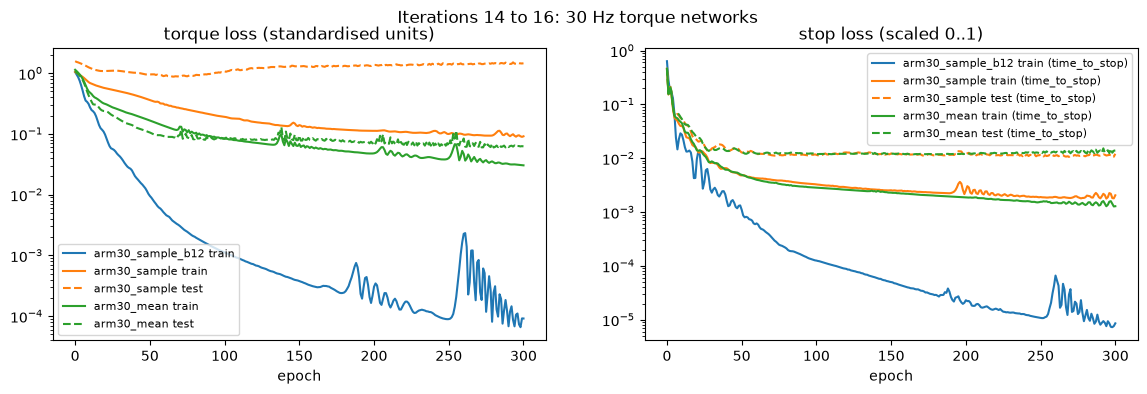

In [62]:
def arm_loss_plot(names, title):
    """Per-epoch training (solid) and test (dashed) losses of arm networks, from models/NAME_history.json."""
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    for name in names:
        h = pd.DataFrame(json.loads((ARM / f'models/{name}_history.json').read_text()))
        line, = ax[0].plot(h.epoch, h.train_torque_mse, label=f'{name} train')
        stop = 'time_to_stop' if 'train_time_to_stop_mse' in h else 'distance'      # what the stop head learns
        ax[1].plot(h.epoch, h[f'train_{stop}_mse'], color=line.get_color(), label=f'{name} train ({stop})')
        if not name.endswith('_b12'):               # trained on one bearing: no test curve
            ax[0].plot(h.epoch, h.test_torque_mse, '--', color=line.get_color(), label=f'{name} test')
            ax[1].plot(h.epoch, h[f'test_{stop}_mse'], '--', color=line.get_color(), label=f'{name} test ({stop})')
    for a, t in zip(ax, ('torque loss (standardised units)', 'stop loss (scaled 0..1)')):
        a.set(yscale='log', xlabel='epoch', title=t); a.legend(fontsize=8)
    fig.suptitle(title); plt.show()

arm_loss_plot(['arm30_sample_b12', 'arm30_sample', 'arm30_mean'], 'Iterations 14 to 16: 30 Hz torque networks')

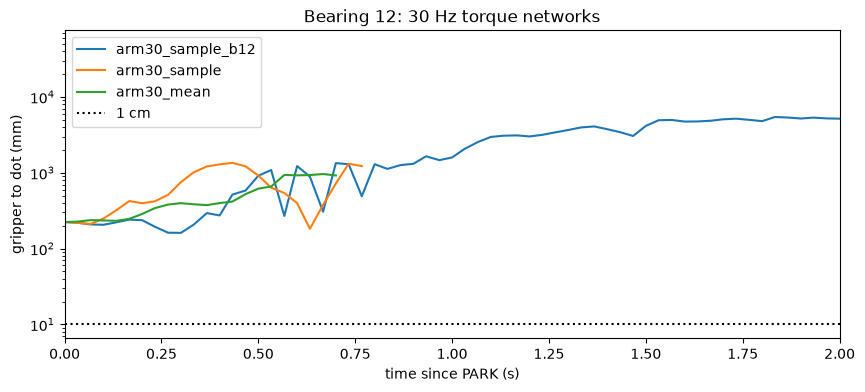

In [63]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ('arm30_sample_b12', 'arm30_sample', 'arm30_mean'):
    r = next(r for r in json.loads((ARM / f'results/{name}.json').read_text()) if r['bearing'] == 12)
    ax.plot([l['t'] - r['log'][0]['t'] for l in r['log']], [l['ee_mm'] for l in r['log']], label=name)
ax.axhline(10, color='k', ls=':', label='1 cm')
ax.set(yscale='log', xlabel='time since PARK (s)', ylabel='gripper to dot (mm)', title='Bearing 12: 30 Hz torque networks', xlim=(0, 2))
ax.legend(); plt.show()

Reading the results:

- No network gets the gripper within 1 cm. The gripper starts about 22.5 cm from the dot at PARK. Each network moves it a few centimetres closer, then the arm swings away and passes 1 m from the dot about 0.5 s after PARK.
- The network trained on bearing 12 alone fits its training rows almost exactly (torque loss 0.0001) and still swings away after 0.53 s. So the failure comes from holding the torques for 33 ms, not from the network learning badly.
- The averaged torques are much easier to learn (test loss 0.06 against 1.46), but they fail in the same way.
- Iteration 15 overfits: its test loss is lowest at epoch 70 (0.87) and rises to 1.46 by epoch 300. Iteration 16 does not: its test loss stays near 0.06.
- This matches test 3b: the expert's own controller fails when its torque is held for 33 ms.

What this means for the arm: to output torques, as the expert does, the arm network has to run at the expert's rate, 1 kHz. The next test is the same network at 1 kHz.

#### Iteration 14: 3D replay (`arm30_sample_b12`)

Solid robot: the arm network's run. Cyan ghost: the expert's own run for the same bearing. The expert drives and parks in both runs, so the two robots overlap until PARK. After PARK the solid arm gets only the network's torques. The side table shows the 7 torques of both. A run is cut once the gripper is more than 1.5 m from the dot after PARK.

The line under the player gives the distance from each gripper to the dot in mm, for the network and the expert. This is the distance the expert itself uses: from its end-effector frame (`robot_j2s7s300_end_effector`) to the dot centre. After PARK the dot is never more than 0.53 m from the shoulder, inside the expert's 0.85 m reach limit, so the expert always aims at the dot centre itself.

<a href="/files/arm/results/viewer_arm30_sample_b12.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [64]:
import sys
sys.path.insert(0, str(ARM.resolve()))
import replay_arm
path = replay_arm.build_viewer('arm30_sample_b12')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 15: 3D replay (`arm30_sample`)

<a href="/files/arm/results/viewer_arm30_sample.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [65]:
path = replay_arm.build_viewer('arm30_sample')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 16: 3D replay (`arm30_mean`)

<a href="/files/arm/results/viewer_arm30_mean.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [66]:
path = replay_arm.build_viewer('arm30_mean')
lazy_player('/files/arm/results/' + path.name)

### Arm: 1 kHz torque network (iteration 17)

#### Iteration 17: plan and expected results

This entry was added after the run. The expectation below is the one stated before training.

The same network as iteration 15 (`arm30_sample`), with one change: it runs every 1 ms, the rate at which the expert outputs its torques (`train_arm.py --hz 1000`).

- Rows: every 1 ms from the expert's PARK to its stop, 75,949 rows over the 21 training runs.
- The encoder speed is the change in angle over 1 ms. The dot position and the times are read every 1 ms too.
- Test: the network's torques are sent every 1 ms through the arm input (`test_arm.py`), on the 25 bearings, with the expert driving.

Expected: the arm should stay stable, because test 3b showed the expert's own torques work at 1 kHz. The risk is drift: the expert's torque depends on a target angle it updates internally every 1 ms (`controller.cpp:81-85`), which the network cannot see, so it has to approximate it from the angles, speeds and times.

In [67]:
rows = []
for name in ('arm30_sample', 'arm1k'):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        rows.append(dict(model=name, split=r['split'], bearing=r['bearing'], train=h['train_torque_mse'], test=h['test_torque_mse'],
                         closest_mm=r['min_mm'], at_expert_stop_mm=r['at_expert_stop_mm'], stopped=r['stop_s'] is not None,
                         stop_vs_expert_s=np.nan if r['stop_s'] is None else r['stop_s'] - r['expert_stop_s']))
arm1k = pd.DataFrame(rows)
arm1k.groupby('model', sort=False).agg(**{
    'train torque loss': ('train', 'first'), 'test torque loss': ('test', 'first'),
    'median closest (mm)': ('closest_mm', 'median'), 'closest within 1 cm (of 25)': ('closest_mm', lambda s: int((s <= 10).sum())),
    'median at the expert stop (mm)': ('at_expert_stop_mm', 'median'), 'stopped (of 25)': ('stopped', 'sum'),
    'median stop vs expert (s)': ('stop_vs_expert_s', 'median')}).round(3)

,train torque loss,test torque loss,median closest (mm),closest within 1 cm (of 25),median at the expert stop (mm),stopped (of 25),median stop vs expert (s)
model,,,,,,,
arm30_sample,0.091,1.456,188.806,0,7082.420,6,-2.648
arm1k,0.078,0.572,18.325,2,124.103,22,-0.969


#### Iteration 17: loss curves

The 1 kHz network against iteration 15 at 30 Hz, in standardised units.

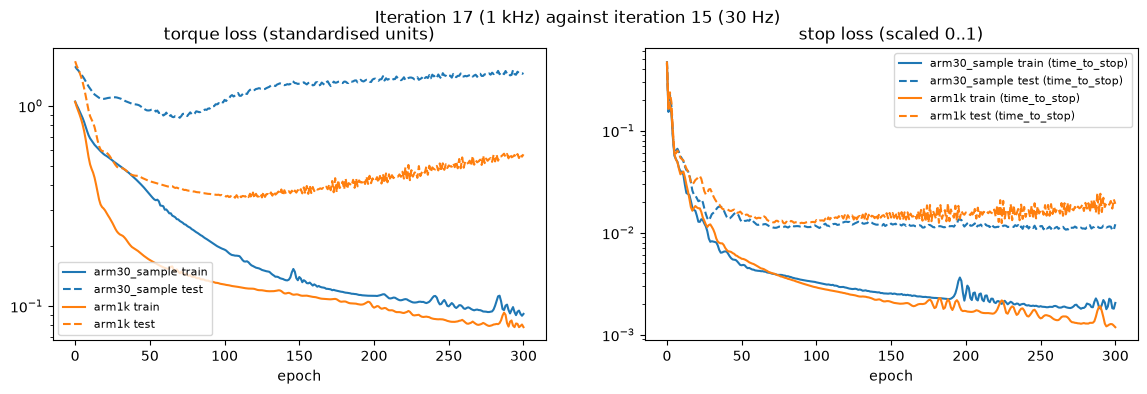

In [68]:
arm_loss_plot(['arm30_sample', 'arm1k'], 'Iteration 17 (1 kHz) against iteration 15 (30 Hz)')

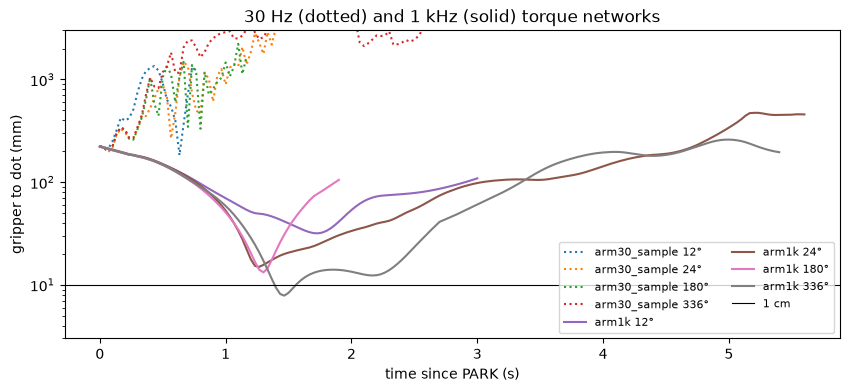

In [69]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, style in (('arm30_sample', ':'), ('arm1k', '-')):
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        if r['bearing'] in (12, 24, 180, 336):
            ax.plot([l['t'] - r['log'][0]['t'] for l in r['log']], [l['ee_mm'] for l in r['log']], style, label=f"{name} {r['bearing']}°")
ax.axhline(10, color='k', lw=0.8, label='1 cm')
ax.set(yscale='log', ylim=(3, 3000), xlabel='time since PARK (s)', ylabel='gripper to dot (mm)', title='30 Hz (dotted) and 1 kHz (solid) torque networks')
ax.legend(ncol=2, fontsize=8); plt.show()

#### Iteration 17: 3D replay (`arm1k`)

<a href="/files/arm/results/viewer_arm1k.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [70]:
path = replay_arm.build_viewer('arm1k')
lazy_player('/files/arm/results/' + path.name)

Reading the results:

- At 1 kHz the arm stays stable. The gripper gets to a median of 18 mm from the dot, against 189 mm at 30 Hz, and within 1 cm on 2 bearings (192° and 336°, both training bearings).
- It does not stay there. After its closest point the gripper drifts away, and at the expert's stop it is a median 124 mm from the dot.
- The network says stop on 22 of 25 bearings, usually early: a median 1.0 s before the expert.
- Test torque loss is 0.57 against 0.08 on training. The test loss is lowest at epoch 120 (0.35) and rises after that, so the network overfits the 21 training reaches. Stopping training earlier is worth testing.
- The likely cause of the drift: the expert's torque depends on a target angle it updates internally every 1 ms (`controller.cpp:81-85`), which the network cannot see. Small torque errors also add up with nothing to correct them.

### Arm: fewer epochs (iteration 18)

#### Iteration 18: plan and expected results

Iteration 17 overfits: its test torque loss is lowest at epoch 120 (0.35) and rises to 0.57 by epoch 300, while the training loss keeps falling. Iteration 18 is the same 1 kHz network trained for fewer epochs.

How the number of epochs is chosen, without using the test bearings:

- The 21 training bearings are already split into 5 folds (`split_plan.json`). For each fold, a network is trained on the other 4 folds for 300 epochs, and its torque loss on the held-out fold is recorded every epoch.
- The number of epochs is the one where the held-out loss, averaged over the 5 folds, is lowest.
- Iteration 18 is then trained on all 21 training bearings for that many epochs. Everything else is as in iteration 17.

Seeds: iteration 18 is trained with seeds 7, 1, 2 and 3. Iteration 17 so far has only seed 7, so it is also trained with seeds 1, 2 and 3 (300 epochs), to compare the two over the same four seeds.

Test: as iteration 17, in the simulator on the 25 bearings with the expert driving.

Expected:

- The chosen number of epochs is between 80 and 200, close to where the iteration 17 test loss is lowest.
- The test torque loss is lower than iteration 17's over the four seeds, about 0.35 against 0.57.
- In the simulator the gripper drifts less after its closest point: the median distance at the expert's stop is below iteration 17's (124 mm with seed 7), and the closest distance is no worse (18 mm).

If the test loss falls but the simulator results do not improve, overfitting is not the main reason for the drift. The more likely reason is then the expert's internal target angle, which the network cannot see.

#### Iteration 18: choosing the number of epochs

For each of the 5 folds of training bearings, a network was trained on the other 4 folds for 300 epochs, and its torque loss on the held-out fold was recorded every epoch. The averaged held-out loss is lowest at epoch 77, so iteration 18 is trained for 77 epochs.

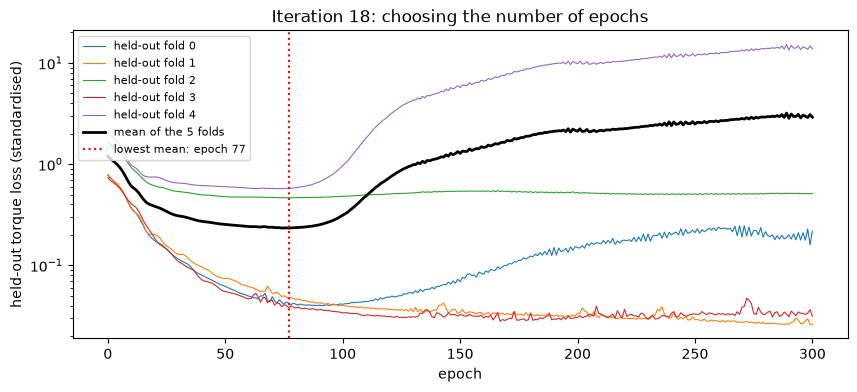

,best_epoch,best_loss,loss_at_300
fold,,,
0,91,0.040,0.217
1,299,0.026,0.026
2,77,0.464,0.513
3,167,0.028,0.031
4,74,0.571,13.757


In [71]:
cv = [pd.DataFrame(json.loads((ARM / f'models/arm1k_cv_fold{f}_history.json').read_text())) for f in range(5)]
mean_val = np.mean([h.val_torque_mse for h in cv], 0)
chosen = json.loads((ARM / 'results/cv_epochs_arm1k.json').read_text())['epochs']
fig, ax = plt.subplots(figsize=(10, 4))
for f, h in enumerate(cv):
    ax.plot(h.epoch, h.val_torque_mse, lw=0.8, label=f'held-out fold {f}')
ax.plot(cv[0].epoch, mean_val, 'k', lw=2, label='mean of the 5 folds')
ax.axvline(chosen, color='r', ls=':', label=f'lowest mean: epoch {chosen}')
ax.set(yscale='log', xlabel='epoch', ylabel='held-out torque loss (standardised)', title='Iteration 18: choosing the number of epochs')
ax.legend(fontsize=8); plt.show()
pd.DataFrame([dict(fold=f, best_epoch=int(h.epoch[h.val_torque_mse.idxmin()]),
                   best_loss=h.val_torque_mse.min(), loss_at_300=h.val_torque_mse.iloc[-1]) for f, h in enumerate(cv)]).set_index('fold').round(3)

#### Iteration 18: results over four seeds

Iteration 17 (300 epochs) against iteration 18 (77 epochs), each with seeds 7, 1, 2 and 3, tested in the simulator on the 25 bearings with the expert driving.

In [72]:
NETS = {17: ['arm1k', 'arm1k_seed1', 'arm1k_seed2', 'arm1k_seed3'], 18: ['arm1k_e77', 'arm1k_e77_seed1', 'arm1k_e77_seed2', 'arm1k_e77_seed3']}
rows = []
for it, names in NETS.items():
    for name, seed in zip(names, (7, 1, 2, 3)):
        h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
        r = pd.DataFrame(json.loads((ARM / f'results/{name}.json').read_text()))
        rows.append({'iteration': it, 'seed': seed, 'model': name, 'epochs': h['epoch'], 'test torque loss': h['test_torque_mse'],
                     'train time-to-stop loss': h['train_time_to_stop_mse'], 'median closest (mm)': r.min_mm.median(),
                     'closest within 1 cm (of 25)': int((r.min_mm <= 10).sum()), 'median at the expert stop (mm)': r.at_expert_stop_mm.median(),
                     'stopped (of 25)': int(r.stop_s.notna().sum())})
iter18 = pd.DataFrame(rows)
display(iter18.set_index(['iteration', 'seed']).round(3))
iter18.drop(columns=['seed', 'model']).groupby('iteration').mean().round(3)

model  epochs  test torque loss  \
iteration seed                                              
17        7               arm1k     300             0.572   
          1         arm1k_seed1     300             0.482   
          2         arm1k_seed2     300             0.811   
          3         arm1k_seed3     300             0.694   
18        7           arm1k_e77      77             0.377   
          1     arm1k_e77_seed1      77             0.367   
          2     arm1k_e77_seed2      77             0.377   
          3     arm1k_e77_seed3      77             0.385   

                train time-to-stop loss  median closest (mm)  \
iteration seed                                                 
17        7                       0.001               18.325   
          1                       0.002               16.456   
          2                       0.001               19.862   
          3                       0.001               37.845   
18        7                       0.004               32.971   
          1                       0.004               18.923   
          2                       0.004               26.687   
          3                       0.003               17.870   

                closest within 1 cm (of 25)  median at the expert stop (mm)  \
iteration seed                                                                
17        7                               2                         124.103   
          1                               6                         100.728   
          2                               4                          74.951   
          3                               0                         488.239   
18        7                               4                         278.746   
          1                               3                         209.033   
          2                               0                         152.882   
          3                               2                         118.563   

                stopped (of 25)  
iteration seed                   
17        7                  22  
          1                  14  
          2                  15  
          3                  22  
18        7                  15  
          1                   6  
          2                   6  
          3                   1

,epochs,test torque loss,train time-to-stop loss,median closest (mm),closest within 1 cm (of 25),median at the expert stop (mm),stopped (of 25)
iteration,,,,,,,
17,300.0,0.640,0.001,23.122,3.00,197.005,18.25
18,77.0,0.376,0.004,24.113,2.25,189.806,7.00


#### Iteration 18: loss curves

Training (solid) and test (dashed) losses for the four seeds of each iteration, in standardised units.

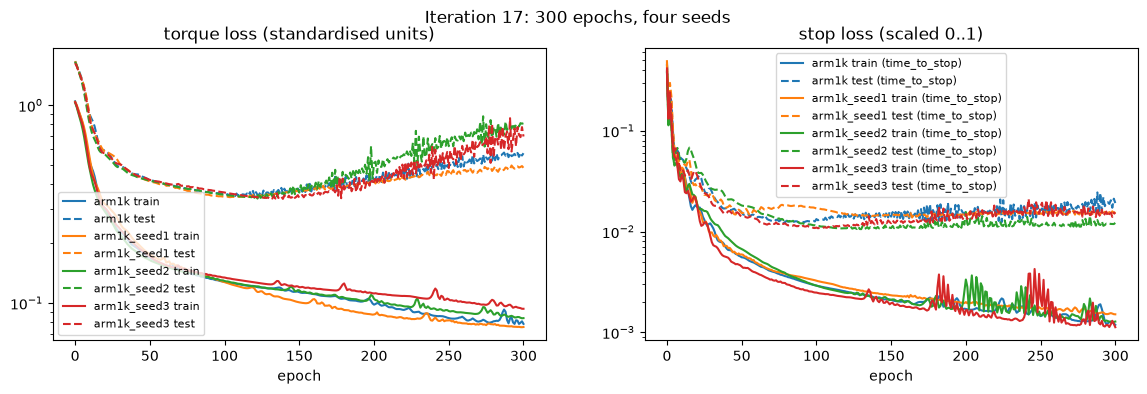

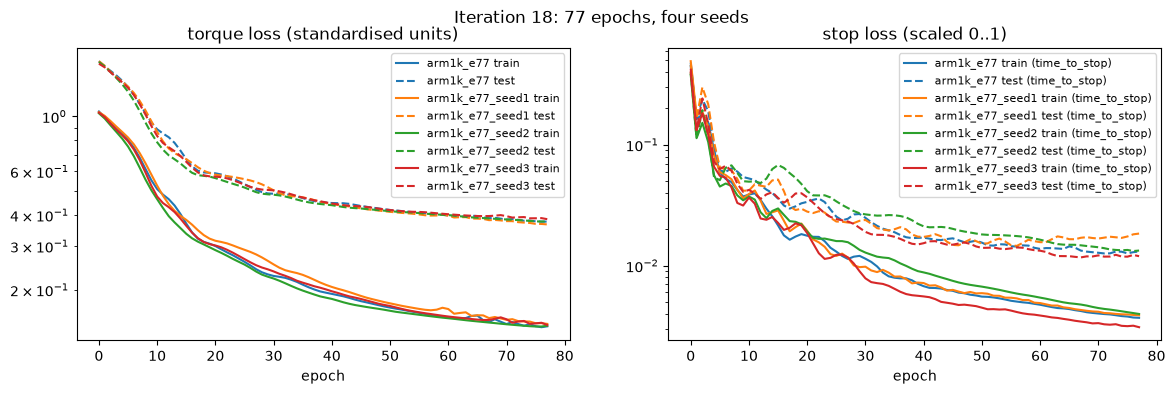

In [73]:
arm_loss_plot(NETS[17], 'Iteration 17: 300 epochs, four seeds')
arm_loss_plot(NETS[18], 'Iteration 18: 77 epochs, four seeds')

#### Iteration 18: 3D replays

One player per network: the four seeds of iteration 18, then the three new seeds of iteration 17 (seed 7 is in the iteration 17 section). The line under each player gives the distance from each gripper to the dot in mm.

##### Iteration 18, seed 7 (`arm1k_e77`)

<a href="/files/arm/results/viewer_arm1k_e77.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [74]:
path = replay_arm.build_viewer('arm1k_e77')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 1 (`arm1k_e77_seed1`)

<a href="/files/arm/results/viewer_arm1k_e77_seed1.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [75]:
path = replay_arm.build_viewer('arm1k_e77_seed1')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 2 (`arm1k_e77_seed2`)

<a href="/files/arm/results/viewer_arm1k_e77_seed2.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [76]:
path = replay_arm.build_viewer('arm1k_e77_seed2')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 3 (`arm1k_e77_seed3`)

<a href="/files/arm/results/viewer_arm1k_e77_seed3.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [77]:
path = replay_arm.build_viewer('arm1k_e77_seed3')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 1 (`arm1k_seed1`)

<a href="/files/arm/results/viewer_arm1k_seed1.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [78]:
path = replay_arm.build_viewer('arm1k_seed1')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 2 (`arm1k_seed2`)

<a href="/files/arm/results/viewer_arm1k_seed2.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [79]:
path = replay_arm.build_viewer('arm1k_seed2')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 3 (`arm1k_seed3`)

<a href="/files/arm/results/viewer_arm1k_seed3.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [80]:
path = replay_arm.build_viewer('arm1k_seed3')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 18: reading the results

Against the expectation:

- **Number of epochs:** 77, just below the expected 80 to 200. The mean is pulled down mostly by fold 4, whose held-out loss rises from 0.57 at epoch 74 to 13.8 at epoch 300. Folds 1 and 3 keep improving until epochs 299 and 167, so the choice depends heavily on one fold.
- **Test torque loss: as expected.** It falls from a mean of 0.64 to 0.38 over the four seeds, and it is much steadier across seeds (0.37 to 0.39, against 0.48 to 0.81).
- **Simulator: not as expected.** The reach does not improve. Over the four seeds the median closest distance is 24.1 mm against 23.1 mm, the gripper gets within 1 cm on 2.25 bearings against 3, and the median distance at the expert's stop is 190 mm against 197 mm.
- **Stop: worse.** The network says stop on 7 of 25 bearings against 18.25. With fewer epochs the time-to-stop output is fitted less closely (training loss 0.004 against 0.001), so it rarely drops below the 0.25 s threshold.
- The seed still matters more than the number of epochs. With 300 epochs, the median distance at the expert's stop ranges from 75 mm (seed 2) to 488 mm (seed 3).

What it tells us: as the plan said, a lower test loss without a better reach in the simulator means overfitting is not the main reason the arm drifts. The more likely reason is the expert's internal target angle, which the network cannot see. Inputs that let the network infer it, such as its previous torques or a short history of joint angles, are the next thing to test. Fewer epochs is not kept, because it costs the stop.

### Arm: stop on distance (iteration 19)

#### Iteration 19: plan and expected results

In iterations 17 and 18 the arm follows the expert's reach closely, but the network does not know when it has reached the dot. The expert gets within 15 mm of the dot about 2 s after PARK and then holds the arm almost still until its stop rule allows it to stop: within 1 cm and more than 8 s since the start. That hold lasts a median 1.6 s. The network drifts during it, and when it does say stop the gripper is already far away: a median 257 mm for iteration 18, seed 7.

Iteration 19 is iteration 18, seed 7, with one change: the stop head learns the distance from the gripper to the dot instead of the time to stop.

- Stop target: the distance from the expert's end effector to the dot centre at each row, from the expert's recordings, clipped at 0.25 m and scaled to 0..1. The network says stop when its predicted distance is 1 cm or less, latched.
- Everything else is as in iteration 18: the same 19 inputs (arm encoder angles and speeds, the dot position from the simulator, time since PARK and since the start), 2×64 ReLU, 1 kHz, 77 epochs, seed 7, rows from the expert's PARK to its stop.
- The loss is the torque loss plus the distance loss, each training run counted equally.
- Test: the 25 bearings in the simulator with the expert driving, as before.
- New result: the distance from the gripper to the dot when the network says stop. A run ends 0.5 s after stop, so the distance 0.5 s later is also reported.

The network has every input it needs for the distance: the 7 joint angles fix where the gripper is, and the dot position is given. It has to learn that mapping from 21 reaches.

Expected:

- The network says stop on at least 20 of the 25 bearings, against 15 for iteration 18, seed 7.
- When it says stop, the gripper is a median 20 mm or less from the dot, against 257 mm.
- It stops earlier than the expert, about 1.5 s before, because it no longer waits for the expert's 8 s rule.
- The reach itself is unchanged: the median closest distance stays near 33 mm.

The expectation is wrong if the network stops on fewer than 15 bearings or the median distance at stop is above 30 mm. That would mean 21 reaches are not enough to learn the distance from the joint angles.

#### Iteration 19: results

Iteration 18, seed 7 (stop on time) against iteration 19 (stop on distance), on the 25 bearings with the expert driving. A run ends 0.5 s after the network says stop.

In [81]:
rows = []
for it, name, stop in ((18, 'arm1k_e77', 'time'), (19, 'arm1k_e77_dist', 'distance')):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    r = pd.DataFrame(json.loads((ARM / f'results/{name}.json').read_text()))
    if 'at_network_stop_mm' not in r:          # older result files: read it from the log
        r['at_network_stop_mm'] = [next((l['ee_mm'] for l in x['log'] if l['t'] >= x['stop_s']), np.nan) if x['stop_s'] else np.nan
                                   for x in json.loads((ARM / f'results/{name}.json').read_text())]
    rows.append({'iteration': it, 'model': name, 'stop learns': stop, 'test torque loss': h['test_torque_mse'],
                 'stopped (of 25)': int(r.stop_s.notna().sum()), 'median distance at stop (mm)': r.at_network_stop_mm.median(),
                 'median distance at the end of the run (mm)': r.end_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'median stop vs expert (s)': (r.stop_s - r.expert_stop_s).median()})
pd.DataFrame(rows).set_index('iteration').round(3)

,model,stop learns,test torque loss,stopped (of 25),median distance at stop (mm),median distance at the end of the run (mm),median closest (mm),median stop vs expert (s)
iteration,,,,,,,,
18,arm1k_e77,time,0.377,15,257.271,445.634,32.971,-0.191
19,arm1k_e77_dist,distance,0.368,25,35.219,62.868,29.332,-1.881


#### Iteration 19: predicted against actual distance

The stop head's predicted distance against the real distance from the gripper to the dot, on four bearings. The network says stop when its prediction first reaches 1 cm (dotted line).

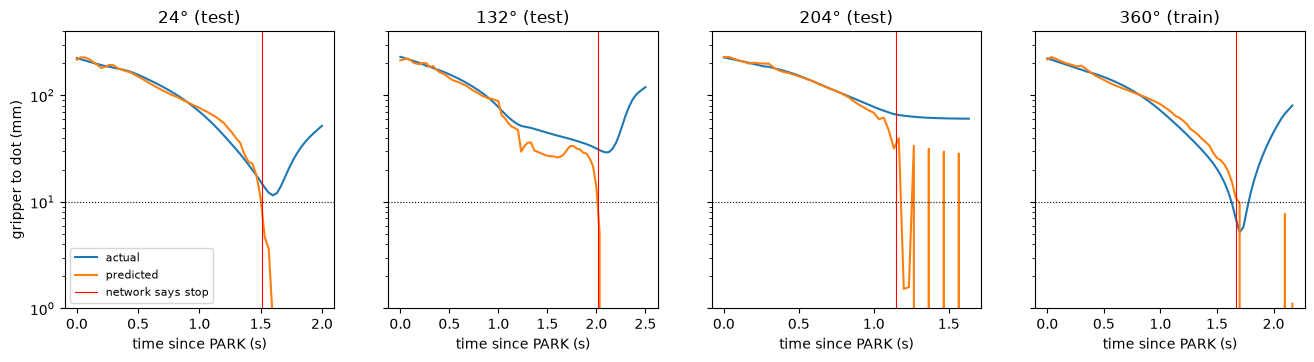

Within 100 mm of the dot: predicted minus actual distance, median -14.2 mm, mean absolute 28.8 mm
Network stops within 10 mm of the closest point it reaches: 18 of 25


In [82]:
r19 = {r['bearing']: r for r in json.loads((ARM / 'results/arm1k_e77_dist.json').read_text())}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, b in zip(axes, (24, 132, 204, 360)):
    L = r19[b]['log']; t0 = L[0]['t']
    ax.plot([l['t'] - t0 for l in L], [l['ee_mm'] for l in L], label='actual')
    ax.plot([l['t'] - t0 for l in L], [1000 * l['ttp_s'] for l in L], label='predicted')
    ax.axhline(10, color='k', ls=':', lw=0.8)
    if r19[b]['stop_s']:
        ax.axvline(r19[b]['stop_s'] - t0, color='r', lw=0.8, label='network says stop')
    ax.set(title=f"{b}° ({r19[b]['split']})", xlabel='time since PARK (s)', yscale='log', ylim=(1, 400))
axes[0].set_ylabel('gripper to dot (mm)'); axes[0].legend(fontsize=8); plt.show()
near = np.array([1000 * l['ttp_s'] - l['ee_mm'] for r in r19.values() for l in r['log'] if l['ee_mm'] < 100])
print(f'Within 100 mm of the dot: predicted minus actual distance, median {np.median(near):.1f} mm, mean absolute {np.abs(near).mean():.1f} mm')
print('Network stops within 10 mm of the closest point it reaches:', sum(r['at_network_stop_mm'] - r['min_mm'] <= 10 for r in r19.values()), 'of 25')

#### Iteration 19: loss curves

Training (solid) and test (dashed) losses. The right panel is the stop loss: time to stop for iteration 18 and distance for iteration 19, each scaled to 0..1, so the two are not on the same scale.

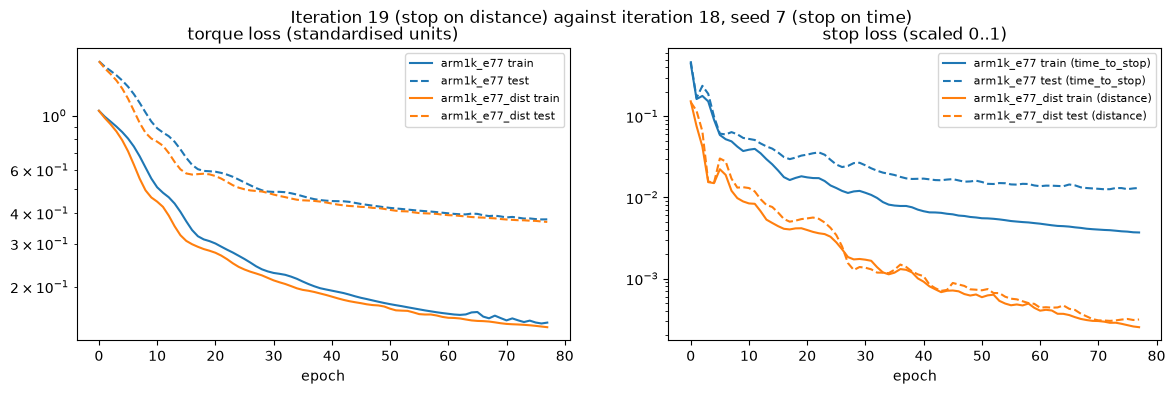

In [83]:
arm_loss_plot(['arm1k_e77', 'arm1k_e77_dist'], 'Iteration 19 (stop on distance) against iteration 18, seed 7 (stop on time)')

#### Iteration 19: 3D replay (`arm1k_e77_dist`)

<a href="/files/arm/results/viewer_arm1k_e77_dist.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [84]:
path = replay_arm.build_viewer('arm1k_e77_dist')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 19: reading the results

Against the expectation:

- **Stops: as expected.** The network says stop on all 25 bearings, against 15 for iteration 18, seed 7.
- **Distance at stop: better, but not as expected.** The gripper is a median 35 mm from the dot when the network says stop, against 257 mm for iteration 18. The expectation was 20 mm or less, and above 30 mm counts as wrong.
- **When it stops: as expected.** A median 1.9 s before the expert, because it no longer waits for the expert's 8 s rule.
- **Reach: as expected.** The median closest distance is 29 mm, against 33 mm.

Why the distance at stop is 35 mm and not 1 cm:

- On 18 of 25 bearings the network says stop within 10 mm of the closest point the gripper reaches. The stop now comes at the right moment; the gripper simply never gets within 1 cm.
- Near the dot the stop head underestimates the distance: when the gripper is within 100 mm, the prediction is a median 14 mm too low. It seems to have learned "this stage of the reach means close" from the 21 expert reaches, where the gripper always ends within about 1 cm, rather than the real distance.
- After stop the distance grows from a median 35 mm to 63 mm over the last 0.5 s, because nothing holds the arm.
- The distance loss is still falling at epoch 77 (training 0.0003, test 0.0003), so the stop head has not finished learning. On 204°, a test bearing where the expert itself stalls 11.5 mm away, the gripper stays about 60 mm away and the prediction falls below 1 cm anyway.

What it tells us: the stop works on distance far better than on time, so it is kept. The limit is now the reach itself. The gripper gets a median 29 mm from the dot, never within 1 cm, and drifts once it stops moving towards it. Getting closer and holding still are the next problems.